# Expresión humana en obras de arte: CNN, filtrado PDI y neutralidad facial

**Procesamiento Digital de Imágenes · UAO 2026-2** · Jose Gabriel Castañeda Uribe · Juan José Osorio Reyes

**Problema.** Una obra transmite emoción por dos canales: su apariencia global (color, iluminación, textura) y la expresión de los rostros que contiene. Este notebook analiza ambos:

- clasifica la obra como **positiva o negativa** con una ResNet-18 preentrenada (transfer learning) ajustada con un dataset propio de 800 obras etiquetadas;
- detecta cada rostro y decide si su expresión es **neutral o no neutral**, con su probabilidad;
- explora la estructura visual de las obras con **agrupamiento no supervisado**.

**Objetivos.**

1. Construir y validar un dataset propio en tres grupos (positivo, negativo y precargadas).
2. Aplicar filtrado espacial (mediana), en frecuencia (homomórfico) y normalización estadística, y medir su efecto.
3. Entrenar y evaluar la CNN binaria con accuracy, precision, recall, F1 y matriz de confusión.
4. Clasificar la neutralidad facial con un preprocesamiento idéntico en todos los flujos y un umbral justificado.
5. Ofrecer todo en una interfaz web en español.

**Cómo usarlo.** Copia las imágenes en las carpetas indicadas en la sección 2 y usa **Ejecutar todo**. Si las carpetas están vacías, el notebook las crea y se ejecuta igualmente: omite el entrenamiento y deja lista la interfaz para cargar los datos después.

| Sección | Contenido |
|---|---|
| 1 | Importaciones, configuración e instalación de dependencias |
| 2 | Carga y extracción del dataset (carpeta local o Google Drive) |
| 3 | Preprocesamiento, entrenamiento de la CNN y análisis de rostros |
| 4 | Predicción sobre imágenes nuevas |
| 5 | Resultados, conclusiones e interfaz web |

> Requisitos: Python 3.10 o superior. La cámara solo funciona en `http://localhost` (o en la ventana que abre Colab): abre la app desde el enlace de la última celda.

## 1. Importaciones, configuración e instalación de dependencias
Se instalan solo las librerías que falten, se importa todo lo necesario y se definen **en una sola celda** las rutas y parámetros editables. Es la única celda que hace falta modificar.

### Dependencias
Solo se instala lo que falte. Ninguna librería es nueva respecto al proyecto: PyTorch y torchvision (CNN), OpenCV y onnxruntime (rostros), scikit-learn (métricas, K-means, PCA), Pillow, NumPy, Matplotlib y FastAPI/uvicorn (interfaz).

In [1]:
import importlib.util
import subprocess
import sys

assert sys.version_info >= (3, 10), "Se requiere Python 3.10 o superior"

REQUERIDAS = {
    "fastapi": "fastapi", "uvicorn": "uvicorn", "multipart": "python-multipart",
    "numpy": "numpy", "PIL": "pillow", "cv2": "opencv-python", "onnxruntime": "onnxruntime",
    "torch": "torch", "torchvision": "torchvision", "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
}
faltan = [pip for modulo, pip in REQUERIDAS.items() if importlib.util.find_spec(modulo) is None]
if faltan:
    print("Instalando:", ", ".join(faltan))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan])
    importlib.invalidate_caches()
print("Python", sys.version.split()[0], "· dependencias listas")

Instalando: onnxruntime
Python 3.13.16 · dependencias listas


### Importaciones

In [2]:
import base64
import colorsys
import copy
import csv
import hashlib
import io
import json
import os
import random
import re
import shutil
import socket
import sys
import threading
import time
import urllib.parse
import urllib.request
import webbrowser
from pathlib import Path
from typing import List, Optional

os.environ.setdefault("OPENCV_LOG_LEVEL", "ERROR")

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import uvicorn
from fastapi import FastAPI, File, Form, HTTPException, UploadFile
from fastapi.middleware.cors import CORSMiddleware
from fastapi.responses import FileResponse, HTMLResponse, JSONResponse, Response
from PIL import Image, ImageFile, ImageOps, UnidentifiedImageError
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, adjusted_rand_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, f1_score, precision_score, recall_score,
                             roc_auc_score, roc_curve, silhouette_score)
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

def _en_jupyter() -> bool:

    try:
        from IPython import get_ipython
        return get_ipython() is not None
    except ImportError:
        return False


EN_JUPYTER = _en_jupyter()
EN_COLAB = "google.colab" in sys.modules or os.environ.get("COLAB_RELEASE_TAG") is not None
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(max(1, os.cpu_count() or 1))
print("Usando:", device)

Usando: cuda


### Montar Google Drive
Conecta Drive y localiza la carpeta del proyecto (dataset, interfaz y modelos).


In [3]:
URL_CARPETA_PROYECTO = "https://drive.google.com/drive/folders/1J6SQJ1kmxwWx8HDnbH67PjmAuDhnRSeD?usp=drive_link"
NOMBRE_CARPETA_PROYECTO = "Proyecto Final PDI VERSION 3"
_m = re.search(r"/folders/([\w-]+)", URL_CARPETA_PROYECTO) or re.search(r"[?&]id=([\w-]+)", URL_CARPETA_PROYECTO)
ID_CARPETA_PROYECTO = _m.group(1) if _m else URL_CARPETA_PROYECTO.strip()


def _norm(texto: str) -> str:

    import unicodedata
    texto = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return " ".join(texto.lower().replace("_", " ").replace("-", " ").split())


def _contar_imagenes(carpeta: Path, tope: int = 5000) -> int:
    n = 0
    for p in carpeta.rglob("*"):
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            n += 1
            if n >= tope:
                break
    return n


def describir_carpeta(ruta: Path) -> dict:

    datos = next((h for h in ruta.iterdir() if h.is_dir() and _norm(h.name) == "dataset usado"), None)
    web = next((h for h in ruta.iterdir() if h.is_dir() and _norm(h.name) == "interfaz"), None)
    return {"ruta": ruta, "dataset": datos, "interfaz": web, "imagenes": _contar_imagenes(datos) if datos else 0,
            "tiene_web": bool(web and (web / "index.html").exists())}


def ruta_por_id(id_carpeta: str) -> Path | None:

    atajo = Path("/content/drive/MyDrive/.shortcut-targets-by-id") / id_carpeta
    if atajo.is_dir():
        hijos = [d for d in atajo.iterdir() if d.is_dir()]
        if len(hijos) == 1:
            return hijos[0]
    try:
        from google.colab import auth
        from googleapiclient.discovery import build
        auth.authenticate_user()
        servicio = build("drive", "v3", cache_discovery=False)
        partes, actual, base = [], id_carpeta, Path("/content/drive/MyDrive")
        for _ in range(30):
            f = servicio.files().get(fileId=actual, fields="id,name,parents,driveId", supportsAllDrives=True).execute()
            padres = f.get("parents")
            if not padres:
                if actual == id_carpeta:
                    print("La carpeta está compartida contigo pero no está en tu «Mi unidad». En Drive: clic derecho sobre\n"
                          "  la carpeta → «Organizar» → «Agregar acceso directo» → «Mi unidad», y vuelve a ejecutar esta celda.")
                    return None
                if f.get("driveId"):
                    nombre_ud = servicio.drives().get(driveId=f["driveId"], fields="name").execute()["name"]
                    base = Path("/content/drive/Shareddrives") / nombre_ud
                break
            partes.append(f["name"])
            actual = padres[0]
        ruta = base.joinpath(*reversed(partes))
        if ruta.is_dir():
            return ruta
        print("La API de Drive indica la ruta", ruta, "pero no existe en el Drive montado: "
              "probablemente montaste otra cuenta. Ejecuta drive.mount('/content/drive', force_remount=True) y elige la correcta.")
    except Exception as e:
        print("No se pudo resolver el ID con la API de Drive:", type(e).__name__, str(e)[:160])
    return None


def buscar_por_nombre(nombre: str, profundidad: int = 4) -> dict | None:

    raiz_drive = Path("/content/drive")
    bases = [raiz_drive / "MyDrive", *sorted((raiz_drive / "MyDrive" / ".shortcut-targets-by-id").glob("*")),
             *sorted((raiz_drive / "Shareddrives").glob("*"))]
    objetivo, candidatos, vistos = _norm(nombre), [], set()
    for base in bases:
        if not base.is_dir():
            continue
        for actual, dirs, _ in os.walk(base):
            nivel = len(Path(actual).relative_to(base).parts)
            dirs[:] = [d for d in dirs if not d.startswith(".")] if nivel < profundidad else []
            for d in dirs:
                ruta = Path(actual) / d
                if _norm(d) == objetivo and ruta.resolve() not in vistos:
                    vistos.add(ruta.resolve())
                    candidatos.append(describir_carpeta(ruta))
    if not candidatos:
        return None
    candidatos.sort(key=lambda c: (-c["imagenes"], not c["tiene_web"]))
    if len(candidatos) > 1:
        print(f"Se encontraron {len(candidatos)} carpetas «{nombre}» (se usa la de más imágenes):")
        for c in candidatos:
            print(f"   {c['imagenes']:5d} imágenes · interfaz {'sí' if c['tiene_web'] else 'no'} · {c['ruta']}")
    return candidatos[0]


CARPETA_PROYECTO_DRIVE = CARPETA_DATASET_DRIVE = CARPETA_WEB_DRIVE = None
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    _ruta = ruta_por_id(ID_CARPETA_PROYECTO)
    _hallada = describir_carpeta(_ruta) if _ruta else None
    if _hallada:
        print(f"Carpeta del enlace (ID {ID_CARPETA_PROYECTO}) encontrada.")
    else:
        print(f"No se pudo usar el enlace; se busca la carpeta por su nombre «{NOMBRE_CARPETA_PROYECTO}»…")
        _hallada = buscar_por_nombre(NOMBRE_CARPETA_PROYECTO)
    if _hallada:
        CARPETA_PROYECTO_DRIVE, CARPETA_DATASET_DRIVE, CARPETA_WEB_DRIVE = _hallada["ruta"], _hallada["dataset"], _hallada["interfaz"]
        print("Carpeta del proyecto:", CARPETA_PROYECTO_DRIVE)
        print(f"  dataset : {CARPETA_DATASET_DRIVE or 'no encontrada'} ({_hallada['imagenes']} imágenes)")
        print(f"  interfaz: {CARPETA_WEB_DRIVE or 'no encontrada'}")
        if _hallada["imagenes"] == 0:
            print("⚠ «dataset usado» no tiene imágenes en esta carpeta: la CNN no se podrá entrenar.")
    else:
        print(" No se encontró la carpeta del proyecto en el Drive montado.\n"
              "  · Monta la MISMA cuenta que abre el enlace (el «/u/1/» indica tu segunda cuenta):\n"
              "    drive.mount('/content/drive', force_remount=True)\n"
              "  · Si la carpeta te la compartieron: «Compartidos conmigo» → clic derecho → «Organizar» →\n"
              "    «Agregar acceso directo» → «Mi unidad».")
else:
    print("Fuera de Colab: se usan las carpetas junto a este notebook (dataset usado/, interfaz/).")

Mounted at /content/drive


Carpeta del enlace (ID 1J6SQJ1kmxwWx8HDnbH67PjmAuDhnRSeD) encontrada.
Carpeta del proyecto: /content/drive/MyDrive/Proyecto Final PDI VERSION 3
  dataset : /content/drive/MyDrive/Proyecto Final PDI VERSION 3/dataset usado (1100 imágenes)
  interfaz: /content/drive/MyDrive/Proyecto Final PDI VERSION 3/interfaz


### Configuración (única celda editable)

In [4]:
class config:
    # Única celda de configuración: todas las rutas y parámetros editables del proyecto.

    # ======================= FUENTE DE DATOS (edita aquí) =======================
    RAIZ = Path.cwd()
    FUENTE_TIPO = "drive" if EN_COLAB else "local"
    RUTA_LOCAL = RAIZ / "dataset usado"
    CARPETA_PROYECTO = CARPETA_PROYECTO_DRIVE or Path("/content/drive/MyDrive") / NOMBRE_CARPETA_PROYECTO
    RUTA_DRIVE = CARPETA_DATASET_DRIVE or CARPETA_PROYECTO / "dataset usado"
    # ======================= INTERFAZ WEB (edita aquí) =======================
    CARPETA_WEB = CARPETA_WEB_DRIVE or (CARPETA_PROYECTO if EN_COLAB else RAIZ) / "interfaz"
    ARCHIVOS_WEB = {"html": "index.html", "css": "styles.css", "js": "app.js"}
    CREAR_ESTRUCTURA = False
    CLASES = ["negativo", "positivo"]
    NOMBRES_CLASES = {"negativo": "Negativa", "positivo": "Positiva"}

    DIR_TRABAJO = RAIZ / "app_pdi"
    DIR_MODELOS = (CARPETA_PROYECTO / "modelos_app") if CARPETA_PROYECTO_DRIVE else DIR_TRABAJO / "modelos"
    DIR_RESULTADOS = RAIZ / "resultados"
    DIR_ROSTROS_EVAL = (CARPETA_PROYECTO / "rostros_eval") if CARPETA_PROYECTO_DRIVE else RAIZ / "rostros_eval"
    RUTA_CNN = DIR_MODELOS / "cnn_obras.pt"
    RUTA_METRICAS = DIR_MODELOS / "metricas_cnn.json"
    RUTA_PARTICION = DIR_MODELOS / "particion_cnn.json"
    RUTA_UMBRAL = DIR_MODELOS / "umbral_neutralidad.json"
    RUTA_YUNET = DIR_MODELOS / "face_detection_yunet_2023mar.onnx"
    RUTA_FERPLUS = DIR_MODELOS / "emotion-ferplus-8.onnx"
    DIR_MODELOS_SIN_RED = RAIZ / "modelos_rostro"
    URL_YUNET = ("https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/"
                 "face_detection_yunet/face_detection_yunet_2023mar.onnx")
    URL_FERPLUS = ("https://media.githubusercontent.com/media/onnx/models/main/validated/vision/"
                   "body_analysis/emotion_ferplus/model/emotion-ferplus-8.onnx")

    # ======================= DATOS ESPERADOS =======================
    ESPERADO_POR_CLASE = 400
    ESPERADO_PRECARGADAS = (200, 300)
    MIN_POR_CLASE = 20

    # ======================= EJECUCIÓN =======================
    REENTRENAR = False             # False: reutiliza cnn_obras.pt de Drive (NO lo sobrescribe) · True: reentrena y lo REEMPLAZA
    COMPARAR_FILTROS = True
    # Arquitectura que se entrena cuando REENTRENAR = True. Al cargar, la arquitectura se lee del modelo guardado.
    #   "resnet18": ResNet-18 preentrenada en ImageNet (transfer learning; se congelan conv1–layer2)
    #   "cnn3"    : CNN de 3 bloques entrenada desde cero (modelo de la versión anterior)
    ARQUITECTURA = "resnet18"
    LR_RESNET = 1e-4
    PUERTO = 8000
    ABRIR_NAVEGADOR = True
    TUNEL_PUBLICO = True

    # ======================= ENTRENAMIENTO (CNN regularizada: Dropout + Weight Decay + Early Stopping) =======================
    SEED = 42
    IMG_SIZE = 224
    BATCH_SIZE = 16
    EPOCAS = 30
    LR = 1e-3
    DROPOUT = 0.5
    WEIGHT_DECAY = 1e-4
    PACIENCIA = 5
    EXTS = {".jpg", ".jpeg", ".png"}

    # ======================= PREPROCESAMIENTO PDI =======================
    LADO_PREPROCESO = 512
    MEDIA_DEFECTO = [0.5, 0.5, 0.5]
    STD_DEFECTO = [0.5, 0.5, 0.5]

    # ======================= ImageLoader =======================
    FORMATOS_PERMITIDOS = {"JPEG", "PNG"}
    MAX_MB = 10
    MIN_LADO = 32

    # ======================= ResultadoProceso =======================
    UMBRAL_CONFIANZA_OBRA = 0.60
    UMBRAL_CONFIANZA_ROSTRO = 0.80
    UMBRAL_EMOCION = 0.40
    UMBRAL_NEUTRALIDAD = 0.50
    MIN_FOTOS_CALIBRACION = 10
    TAM_MIN_ROSTRO = 0.06
    BRILLO_MIN = 45
    BRILLO_MAX = 225
    NITIDEZ_MIN = 25.0

    # ======================= Paleta, captura y rostros en la imagen =======================
    N_COLORES = 6
    LADO_MUESTREO_PALETA = 160
    MAX_FRAMES = 60
    UMBRAL_ROSTRO_OBRA = 0.60
    TAM_MIN_ROSTRO_OBRA = 0.02
    LADO_MAX_DETECCION = 1280
    DATASET_MAX_ALEATORIAS = 24
    EXTS_IMAGEN = {".jpg", ".jpeg", ".png"}


for _d in (config.DIR_MODELOS, config.DIR_RESULTADOS):
    _d.mkdir(parents=True, exist_ok=True)
for _png in config.DIR_RESULTADOS.glob("[0-9][0-9]_*.png"):
    _png.unlink()
SEED, IMG_SIZE, BATCH_SIZE, CLASES, EXTS = config.SEED, config.IMG_SIZE, config.BATCH_SIZE, config.CLASES, config.EXTS

if not EN_JUPYTER:
    plt.switch_backend("Agg")
_contador_fig = [0]
_show_original = getattr(plt.show, "_original", plt.show)


def mostrar_y_guardar(*_args, **_kwargs):
    """Muestra cada figura abierta (en Jupyter) y la guarda en resultados/ para el README y el póster."""
    for num in plt.get_fignums():
        fig = plt.figure(num)
        titulo = (fig._suptitle.get_text() if fig._suptitle else "") or (fig.axes[0].get_title() if fig.axes else "figura")
        _contador_fig[0] += 1
        nombre = re.sub(r"[^\w-]+", "_", titulo)[:50].strip("_") or "figura"
        fig.savefig(config.DIR_RESULTADOS / f"{_contador_fig[0]:02d}_{nombre}.png", dpi=110, bbox_inches="tight")
    if EN_JUPYTER:
        _show_original()
    plt.close("all")


mostrar_y_guardar._original = _show_original
plt.show = mostrar_y_guardar
print("Fuente de datos:", config.FUENTE_TIPO, "·", config.RUTA_DRIVE if config.FUENTE_TIPO == "drive" else config.RUTA_LOCAL)
print("Modelos en:", config.DIR_MODELOS, "· figuras en:", config.DIR_RESULTADOS)
print("Interfaz web en:", config.CARPETA_WEB)

Fuente de datos: drive · /content/drive/MyDrive/Proyecto Final PDI VERSION 3/dataset usado
Modelos en: /content/drive/MyDrive/Proyecto Final PDI VERSION 3/modelos_app · figuras en: /content/resultados
Interfaz web en: /content/drive/MyDrive/Proyecto Final PDI VERSION 3/interfaz


## 2. Carga y extracción del dataset
Las imágenes se leen de una **carpeta local** o de **Google Drive montado** (en Colab, `/content/drive/MyDrive/...`). Estructura recomendada:

```
dataset usado/
├── Positivo/                ~300 obras de la clase positiva
├── Negativo/                ~300 obras de la clase negativa
├── Precarga sin analizar/   200–300 obras sin etiqueta (base de consulta)
└── etiquetas.csv            opcional: archivo,etiqueta
```
Los nombres no distinguen mayúsculas ni tildes. También se aceptan `positivas`, `negativas`, `precargadas` o `sin analizar`.

**Por qué esta estructura:**

- **La etiqueta es la carpeta.** No hay un archivo de anotaciones que se pueda desincronizar, y `etiquetas.csv`, si existe, solo sirve para comprobarla.
- **Las precargadas van aparte.** Así nunca entran al entrenamiento, y el sistema detecta si alguna está repetida en las etiquetadas, lo que sería una fuga de datos.
- **La misma carpeta sirve en el computador y en Drive.** Solo cambia la ruta en la configuración.

Cada archivo se valida: formato, legibilidad, tamaño, duplicados y conflictos de etiqueta. Al final se informa cuántas imágenes quedaron por grupo y por qué se descartó cada archivo.

### Lectura segura de imágenes
`cargar_imagen` es la única puerta de entrada de imágenes: valida JPG/PNG (≤ 10 MB, ≥ 32 px), corrige la orientación EXIF y entrega RGB.

In [5]:
"""
ImageLoader
-----------
Función: cargar y validar el archivo de imagen seleccionado por el usuario.
Entrada: bytes del archivo (selector de la GUI o fotograma de la cámara). Se admiten JPEG y PNG.
Salida : imagen decodificada en memoria, RGB de 3 canales, con su ancho y alto originales.
Error  : archivo ausente, corrupto o no compatible  ->  ErrorProceso con código controlado.
"""


Image.MAX_IMAGE_PIXELS = 120_000_000


class ErrorProceso(Exception):

    def __init__(self, tipo: str, mensaje: str, gravedad: str = "error", modulo: str = "ImageLoader"):

        super().__init__(mensaje)
        self.tipo = tipo
        self.mensaje = mensaje
        self.gravedad = gravedad
        self.modulo = modulo

    def a_dict(self) -> dict:
        return {"tipo": self.tipo, "gravedad": self.gravedad, "mensaje": self.mensaje, "modulo": self.modulo}


def cargar_imagen(datos: bytes | None, nombre: str = "imagen", permitir_formatos=None) -> np.ndarray:

    permitidos = permitir_formatos or config.FORMATOS_PERMITIDOS
    if not datos:
        raise ErrorProceso("archivo_ausente", f"No se recibió ningún archivo para «{nombre}».")
    if len(datos) > config.MAX_MB * 1024 * 1024:
        raise ErrorProceso("formato", f"«{nombre}» pesa más de {config.MAX_MB} MB. Elige una imagen más ligera.")
    try:
        with Image.open(io.BytesIO(datos)) as im:
            formato = (im.format or "").upper()
            if formato not in permitidos:
                raise ErrorProceso("formato", f"Formato no soportado ({formato or 'desconocido'}). Ingresa una imagen JPG o PNG.")
            im.load()
            im = ImageOps.exif_transpose(im)
            rgb = im.convert("RGB")
    except ErrorProceso:
        raise
    except (UnidentifiedImageError, OSError, ValueError, Image.DecompressionBombError):
        raise ErrorProceso("archivo_corrupto", f"No se pudo leer «{nombre}». El archivo está dañado o no es una imagen válida.")

    w, h = rgb.size
    if w < config.MIN_LADO or h < config.MIN_LADO:
        raise ErrorProceso("fuera_de_rango", f"«{nombre}» es demasiado pequeña ({w}×{h} px). Usa una de al menos {config.MIN_LADO} px por lado.")
    return np.asarray(rgb, dtype=np.uint8)

### Fuente de datos y validación

In [6]:
MODULO = "FuenteDeDatos"
GRUPOS = ("positivo", "negativo", "precargadas")
ALIAS = {
    "positivo": {"positivo", "positivos", "positiva", "positivas", "positive", "pos", "agradable", "agradables"},
    "negativo": {"negativo", "negativos", "negativa", "negativas", "negative", "neg", "inquietante", "inquietantes"},
    "precargadas": {"precargadas", "precargada", "precargados", "precargado", "precarga", "precarga sin analizar",
                    "precargadas sin analizar", "sin analizar", "sin etiqueta", "unlabeled", "consulta", "base"},
}


def normalizar_nombre(nombre: str) -> str:

    import unicodedata
    n = unicodedata.normalize("NFKD", nombre).encode("ascii", "ignore").decode().lower()
    return " ".join(n.replace("_", " ").replace("-", " ").split())
IGNORAR = {".ds_store", "thumbs.db", "desktop.ini", "etiquetas.csv", "readme.md", ".gitkeep"}
_azar = random.SystemRandom()


def _error(tipo: str, mensaje: str, gravedad: str = "error") -> ErrorProceso:
    return ErrorProceso(tipo, mensaje, gravedad, MODULO)


def drive_montado() -> bool:
    try:
        montajes = Path("/proc/mounts").read_text().split("\n")
        en_tabla = any(len(m.split()) > 1 and m.split()[1] == "/content/drive" for m in montajes)
    except OSError:
        en_tabla = False
    return (en_tabla or os.path.ismount("/content/drive")) and Path("/content/drive/MyDrive").is_dir()


def montar_drive_si_hace_falta(ruta: Path) -> None:

    if not str(ruta).startswith("/content/drive") or drive_montado():
        return
    try:
        from google.colab import drive
    except ImportError:
        raise _error("fuente_no_encontrada", f"La ruta «{ruta}» es de Google Colab, pero el notebook no se está "
                                             "ejecutando en Colab. En tu computador usa la carpeta de Google Drive "
                                             "para escritorio (por ejemplo G:\\Mi unidad\\datos) o una carpeta local.")
    if threading.current_thread() is not threading.main_thread():
        raise _error("fuente_no_disponible", "Google Drive no está montado (Colab pudo reiniciar la sesión). Ejecuta en una celda: "
                                             "from google.colab import drive; drive.mount('/content/drive') "
                                             "y vuelve a pulsar «Cargar y validar».")
    punto = Path("/content/drive")
    if punto.is_dir() and not drive_montado():
        if any(p.is_file() for p in punto.rglob("*")):
            raise _error("fuente_no_disponible", "La carpeta local /content/drive contiene archivos y no es tu Drive, por eso no se "
                                                 "puede montar. Reinicia el entorno de ejecución de Colab y vuelve a ejecutar.")
        for d in sorted(punto.rglob("*"), key=lambda p: -len(p.parts)):
            d.rmdir()
    try:
        drive.mount("/content/drive")
    except Exception as e:
        raise _error("fuente_no_disponible", f"No se pudo montar Google Drive: {e}. Vuelve a autorizar el acceso.")
    if not drive_montado():
        raise _error("fuente_no_disponible", "Google Drive no quedó montado. Ejecuta la celda otra vez y acepta la autorización.")


def buscar_carpetas_con_imagenes(base: Path, profundidad: int = 4, limite_dirs: int = 4000) -> list[dict]:

    vistos, salida = 0, []
    if not base.is_dir():
        return salida
    for actual, dirs, _ in os.walk(base):
        vistos += 1
        nivel = len(Path(actual).relative_to(base).parts)
        dirs[:] = [d for d in dirs if not d.startswith(".")] if nivel < profundidad else []
        if vistos > limite_dirs:
            break
        hijos = {normalizar_nombre(d): Path(actual) / d for d in dirs}
        grupos = {g: next((hijos[n] for n in hijos if n in ALIAS[g]), None) for g in GRUPOS}
        if grupos["positivo"] and grupos["negativo"]:
            n = {g: (sum(1 for p in c.rglob("*") if p.suffix.lower() in config.EXTS_IMAGEN) if c else 0) for g, c in grupos.items()}
            if n["positivo"] + n["negativo"] > 0:
                salida.append({"ruta": actual, **n})
    return sorted(salida, key=lambda x: -(x["positivo"] + x["negativo"]))


def _buscar_grupos(raiz: Path) -> dict:

    encontrados = {g: None for g in GRUPOS}
    if not raiz.is_dir():
        return encontrados
    candidatos = [raiz] + [p for p in raiz.iterdir() if p.is_dir()] + \
                 [q for p in raiz.iterdir() if p.is_dir() for q in p.iterdir() if q.is_dir()]
    for base in candidatos:
        hijos = {normalizar_nombre(p.name): p for p in base.iterdir() if p.is_dir()} if base.is_dir() else {}
        hallados = {g: next((hijos[n] for n in hijos if n in ALIAS[g]), None) for g in GRUPOS}
        if hallados["positivo"] and hallados["negativo"]:
            return hallados
        if not any(encontrados.values()) and any(hallados.values()):
            encontrados = hallados
    return encontrados


def _leer_manifiesto(raiz: Path) -> dict:
    for ruta in [raiz / "etiquetas.csv", *raiz.glob("*/etiquetas.csv")]:
        if ruta.is_file():
            salida = {}
            with open(ruta, encoding="utf-8-sig", newline="") as f:
                for fila in csv.DictReader(f):
                    nombre, etiqueta = (fila.get("archivo") or "").strip(), (fila.get("etiqueta") or "").strip().lower()
                    grupo = next((g for g in ("positivo", "negativo") if etiqueta in ALIAS[g]), None)
                    if nombre and grupo:
                        salida[Path(nombre).name] = grupo
            return salida
    return {}


def _validar_archivo(ruta: Path) -> tuple[str | None, str | None, tuple | None]:
    if ruta.suffix.lower() not in config.EXTS_IMAGEN:
        return None, f"extensión «{ruta.suffix or 'sin extensión'}» no soportada (usa JPG o PNG)", None
    try:
        datos = ruta.read_bytes()
    except OSError as e:
        return None, f"no se pudo leer el archivo ({e.strerror})", None
    if len(datos) > config.MAX_MB * 1024 * 1024:
        return None, f"pesa más de {config.MAX_MB} MB", None
    try:
        with Image.open(io.BytesIO(datos)) as im:
            if (im.format or "").upper() not in config.FORMATOS_PERMITIDOS:
                return None, f"el contenido es {im.format or 'desconocido'}, no JPG/PNG", None
            im.load()
            w, h = ImageOps.exif_transpose(im).size
    except (UnidentifiedImageError, OSError, ValueError, Image.DecompressionBombError):
        return None, "ilegible, truncada o no es una imagen", None
    if min(w, h) < config.MIN_LADO:
        return None, f"demasiado pequeña ({w}×{h} px)", None
    return hashlib.md5(datos).hexdigest(), None, (w, h)


def validar_carpeta(raiz: Path, origen: str) -> dict:
    grupos = _buscar_grupos(raiz)
    if not grupos["positivo"] and not grupos["negativo"] and not grupos["precargadas"]:
        raise _error("estructura_invalida",
                     f"En «{raiz}» no hay carpetas positivo/, negativo/ ni precargadas/. "
                     "Organiza las imágenes así: datos/positivo, datos/negativo y datos/precargadas.")
    manifiesto = _leer_manifiesto(raiz)
    hashes: dict[str, list[tuple[str, Path]]] = {}
    imagenes = {g: [] for g in GRUPOS}
    descartadas = []
    for g in GRUPOS:
        carpeta = grupos[g]
        if not carpeta:
            continue
        for ruta in sorted(p for p in carpeta.rglob("*") if p.is_file()):
            if ruta.name.lower() in IGNORAR or ruta.name.startswith("."):
                continue
            rel = str(ruta.relative_to(carpeta))
            h, motivo, _ = _validar_archivo(ruta)
            if motivo:
                descartadas.append({"grupo": g, "archivo": rel, "motivo": motivo})
                continue
            if g != "precargadas" and manifiesto.get(ruta.name) and manifiesto[ruta.name] != g:
                descartadas.append({"grupo": g, "archivo": rel,
                                    "motivo": f"etiquetas.csv dice «{manifiesto[ruta.name]}» pero está en la carpeta «{g}»"})
                continue
            previos = hashes.setdefault(h, [])
            if any(pg == g for pg, _ in previos):
                original = next(r for pg, r in previos if pg == g)
                descartadas.append({"grupo": g, "archivo": rel, "motivo": f"duplicada de «{original.name}» en el mismo grupo"})
                continue
            previos.append((g, ruta))
            imagenes[g].append(ruta)

    for h, lista in hashes.items():
        gs = {g for g, _ in lista}
        if {"positivo", "negativo"} <= gs:
            for g, r in lista:
                if g in ("positivo", "negativo") and r in imagenes[g]:
                    imagenes[g].remove(r)
                    descartadas.append({"grupo": g, "archivo": r.name,
                                        "motivo": "conflicto de etiqueta: la misma imagen está en positivo y en negativo"})
        if "precargadas" in gs and gs & {"positivo", "negativo"}:
            for g, r in lista:
                if g == "precargadas" and r in imagenes[g]:
                    imagenes[g].remove(r)
                    descartadas.append({"grupo": g, "archivo": r.name,
                                        "motivo": "ya está en el conjunto etiquetado (se excluye para evitar fuga de datos)"})

    n = {g: len(imagenes[g]) for g in GRUPOS}
    avisos = []
    if not grupos["precargadas"]:
        avisos.append("No hay carpeta precargadas/: el análisis de consulta solo podrá usar imágenes subidas por el usuario.")
    for g, esperado in (("positivo", config.ESPERADO_POR_CLASE), ("negativo", config.ESPERADO_POR_CLASE)):
        if grupos[g] and n[g] < esperado * 0.8:
            avisos.append(f"{g}: {n[g]} imágenes válidas, menos de las {esperado} previstas.")
    if grupos["precargadas"] and not (config.ESPERADO_PRECARGADAS[0] <= n["precargadas"] <= config.ESPERADO_PRECARGADAS[1]):
        avisos.append(f"precargadas: {n['precargadas']} imágenes (se esperaban entre {config.ESPERADO_PRECARGADAS[0]} y {config.ESPERADO_PRECARGADAS[1]}).")
    if n["positivo"] and n["negativo"]:
        razon = max(n["positivo"], n["negativo"]) / max(1, min(n["positivo"], n["negativo"]))
        if razon > 1.25:
            avisos.append(f"Clases desbalanceadas ({n['positivo']} positivas vs {n['negativo']} negativas): las métricas pueden engañar.")
    listo = n["positivo"] >= config.MIN_POR_CLASE and n["negativo"] >= config.MIN_POR_CLASE
    if not listo:
        avisos.append(f"Se necesitan al menos {config.MIN_POR_CLASE} imágenes válidas por clase para entrenar la CNN.")
    esperado = {"positivo": str(config.ESPERADO_POR_CLASE), "negativo": str(config.ESPERADO_POR_CLASE),
                "precargadas": f"{config.ESPERADO_PRECARGADAS[0]}–{config.ESPERADO_PRECARGADAS[1]}"}
    return {
        "origen": origen,
        "raiz": str(raiz),
        "fecha": time.time(),
        "grupos": {g: {"carpeta": str(grupos[g]) if grupos[g] else None, "validas": n[g],
                       "descartadas": sum(1 for d in descartadas if d["grupo"] == g), "esperado": esperado[g]} for g in GRUPOS},
        "imagenes": {g: [str(p) for p in imagenes[g]] for g in GRUPOS},
        "descartadas": descartadas,
        "manifiesto": bool(manifiesto),
        "avisos": avisos,
        "listo_entrenar": listo,
    }


class FuenteDeDatos:

    def __init__(self):
        self._lock = threading.Lock()
        self.reporte: dict | None = None
        self.parametros: dict | None = None
        self.particion = self._cargar_particion()

    @staticmethod
    def _cargar_particion() -> dict:
        try:
            return json.loads(config.RUTA_PARTICION.read_text(encoding="utf-8"))["archivos"]
        except (OSError, ValueError, KeyError):
            return {}

    def cargar(self, tipo: str = "local", ruta: str = "") -> dict:
        tipo = (tipo or "local").strip().lower()
        if tipo not in ("local", "drive"):
            raise _error("fuente_no_encontrada", f"Tipo de fuente desconocido: «{tipo}». Usa local o drive.")
        with self._lock:
            texto = (ruta or "").strip().strip('"')
            raiz = Path(os.path.expandvars(os.path.expanduser(texto))) if texto else \
                (config.RUTA_DRIVE if tipo == "drive" else config.RUTA_LOCAL)
            if tipo == "drive":
                montar_drive_si_hace_falta(raiz)
            if not raiz.is_dir():
                raise _error("fuente_no_encontrada", f"La carpeta «{raiz}» no existe o no es accesible."
                             + (" Revisa que Drive esté montado y que la carpeta esté en «Mi unidad»." if tipo == "drive" else ""))
            origen = ("Google Drive" if tipo == "drive" else "Carpeta local") + f" ({raiz})"
            self.reporte = validar_carpeta(raiz, origen)
            self.parametros = {"tipo": tipo, "ruta": str(raiz)}
            g = self.reporte["grupos"]
            if g["positivo"]["validas"] + g["negativo"]["validas"] + g["precargadas"]["validas"] == 0 \
                    and not self.reporte["descartadas"]:
                base = Path("/content/drive/MyDrive") if str(raiz).startswith("/content/drive") else raiz.parent
                candidatas = [c for c in buscar_carpetas_con_imagenes(base) if Path(c["ruta"]) != raiz][:3]
                self.reporte["sugerencias"] = candidatas
                if candidatas:
                    self.reporte["avisos"].insert(0, "Las carpetas de «" + str(raiz) + "» están vacías, pero encontré imágenes en: " +
                        "; ".join(f"{c['ruta']} (positivo {c['positivo']}, negativo {c['negativo']}, precargadas {c['precargadas']})"
                                  for c in candidatas) + ". Escribe esa ruta y pulsa «Cargar y validar», o mueve las imágenes a esta carpeta.")
                else:
                    self.reporte["avisos"].insert(0, f"Las carpetas positivo/, negativo/ y precargadas/ de «{raiz}» existen pero están vacías. "
                        "Copia las imágenes dentro de ellas (en Drive, dentro de «Mi unidad»; no en «Compartidos conmigo») "
                        "y vuelve a pulsar «Cargar y validar».")
            return self.resumen()

    def resumen(self) -> dict:
        if not self.reporte:
            return {"cargado": False}
        r = {k: v for k, v in self.reporte.items() if k != "imagenes"}
        r.update({"cargado": True, "parametros": self.parametros})
        return r

    def etiquetadas(self) -> list[tuple[Path, int]]:
        if not self.reporte:
            raise _error("sin_datos", "Primero carga una fuente de datos.")
        return [(Path(p), config.CLASES.index(g)) for g in ("positivo", "negativo") for p in self.reporte["imagenes"][g]]

    def _precargadas(self) -> dict:
        if not self.reporte:
            return {}
        salida = {}
        for p in map(Path, self.reporte["imagenes"]["precargadas"]):
            clave = p.name if p.name not in salida else f"{p.parent.name}/{p.name}"
            salida[clave] = p
        return salida

    def estado(self) -> dict:
        n = len(self._precargadas())
        return {"listo": n > 0, "n_imagenes": n, "origen": self.reporte["origen"] if self.reporte else None,
                "fecha": self.reporte["fecha"] if self.reporte else None, "n_particion_cnn": len(self.particion)}

    def info_imagen(self, nombre: str) -> dict:
        ruta = self._precargadas().get(nombre)
        return {"nombre": nombre, "bytes": ruta.stat().st_size if ruta else None,
                "url": "/api/dataset/imagen?nombre=" + urllib.parse.quote(nombre, safe=""),
                "cnn": self.particion.get(nombre)}

    def aleatorias(self, n: int, excluir: list[str] | None = None) -> dict:
        todas = self._precargadas()
        if not todas:
            raise _error("sin_precargadas", "No hay imágenes precargadas. Carga una fuente con la carpeta precargadas/ "
                                            "o analiza una imagen propia.")
        n = max(1, min(int(n), config.DATASET_MAX_ALEATORIAS))
        excl = set(excluir or [])
        pool = [k for k in todas if k not in excl] or list(todas)
        elegidas = _azar.sample(pool, min(n, len(pool)))
        return {"imagenes": [self.info_imagen(x) for x in elegidas], "total_dataset": len(todas), "avisos": []}

    def ruta(self, nombre: str) -> Path:
        r = self._precargadas().get(nombre)
        if r is None or not r.is_file():
            raise _error("imagen_no_encontrada", f"«{nombre}» no está entre las imágenes precargadas.")
        return r

    def leer(self, nombre: str) -> bytes:
        return self.ruta(nombre).read_bytes()

    def rutas_precargadas(self) -> list[Path]:
        return list(self._precargadas().values())

### Cargar y validar la fuente configurada

Origen: Google Drive (/content/drive/MyDrive/Proyecto Final PDI VERSION 3/dataset usado)
  positivo      400 válidas · 0 descartadas (esperado 400)
  negativo      400 válidas · 0 descartadas (esperado 400)
  precargadas   300 válidas · 0 descartadas (esperado 200–300)


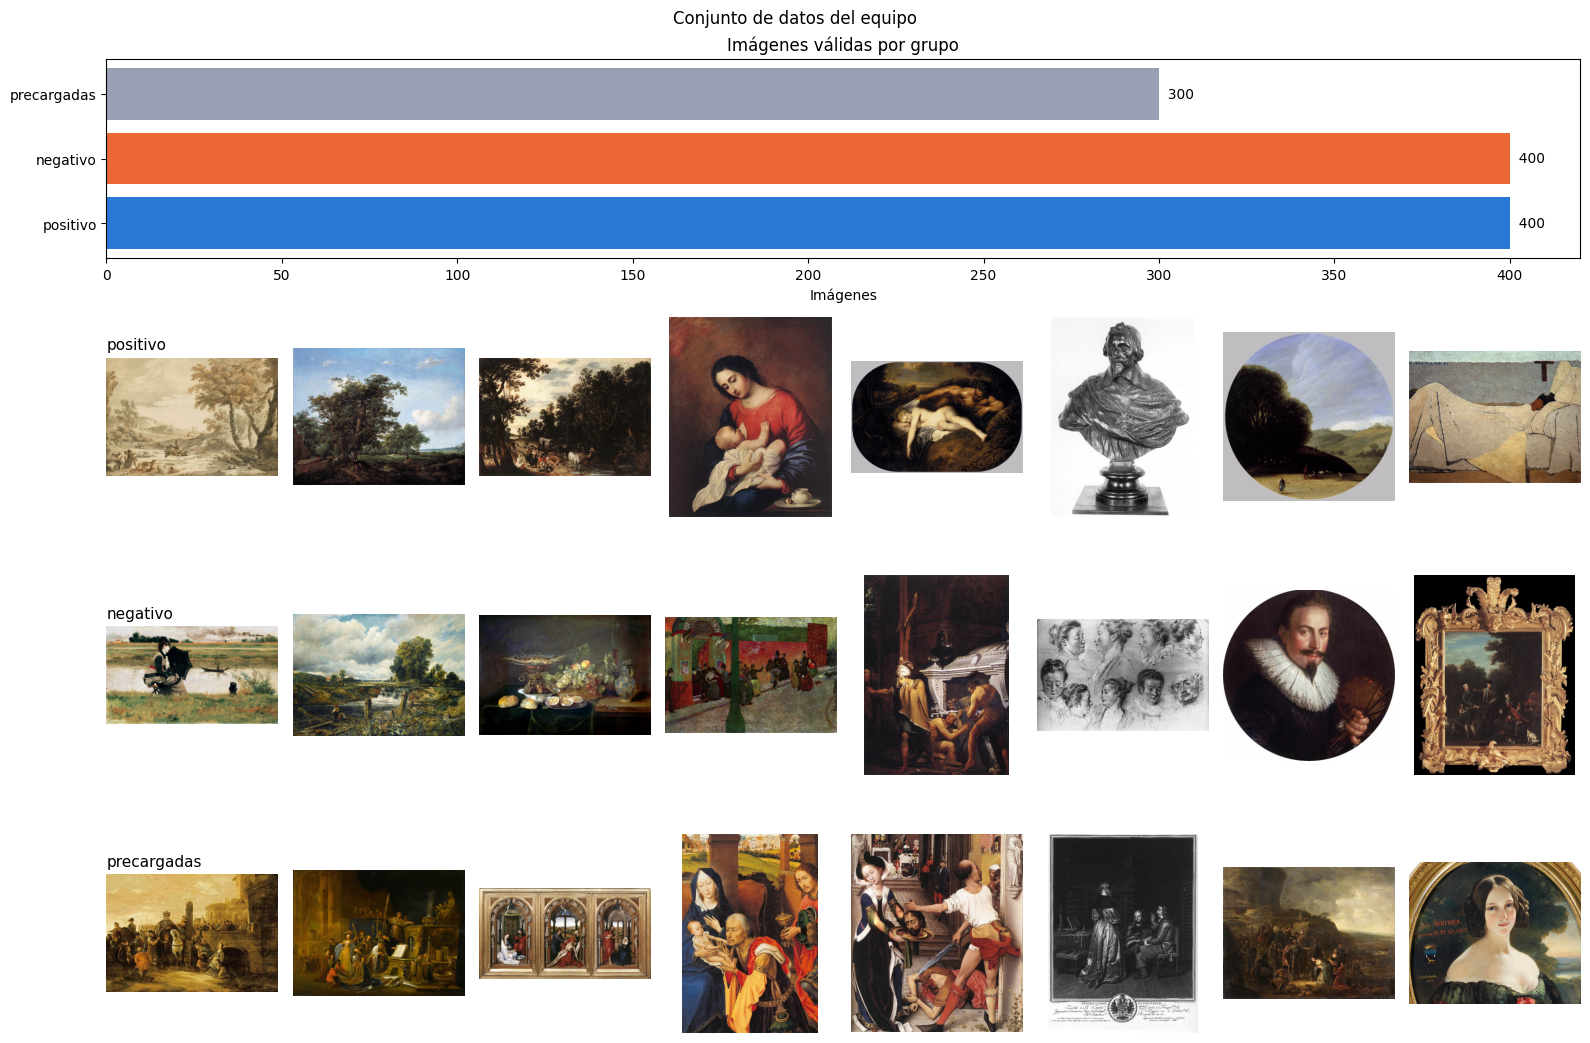

In [7]:
def preparar_estructura(raiz: Path) -> bool:
    if raiz.is_dir() or not config.CREAR_ESTRUCTURA:
        return False
    if str(raiz).startswith("/content/drive") and not drive_montado():
        return False
    for g in GRUPOS:
        (raiz / g).mkdir(parents=True, exist_ok=True)
    return True


def imprimir_reporte(rep: dict) -> None:
    print("Origen:", rep["origen"])
    for g, d in rep["grupos"].items():
        estado = "no encontrada" if not d["carpeta"] else f"{d['validas']:4d} válidas · {d['descartadas']} descartadas (esperado {d['esperado']})"
        print(f"  {g:12s} {estado}")
    if rep["descartadas"]:
        print(f"\nArchivos descartados ({len(rep['descartadas'])}):")
        for d in rep["descartadas"][:40]:
            print(f"  [{d['grupo']}] {d['archivo']}: {d['motivo']}")
        if len(rep["descartadas"]) > 40:
            print(f"  … y {len(rep['descartadas']) - 40} más")
    for a in rep["avisos"]:
        print("Aviso:", a)


fuente = FuenteDeDatos()
reporte = None
raiz_datos = config.RUTA_DRIVE if config.FUENTE_TIPO == "drive" else config.RUTA_LOCAL
try:
    if config.FUENTE_TIPO == "drive":
        montar_drive_si_hace_falta(raiz_datos)
    if preparar_estructura(raiz_datos):
        print(f"Se creó la estructura vacía en {raiz_datos}:\n"
              f"  {raiz_datos / 'positivo'}     ← ~{config.ESPERADO_POR_CLASE} imágenes de la clase positiva\n"
              f"  {raiz_datos / 'negativo'}     ← ~{config.ESPERADO_POR_CLASE} imágenes de la clase negativa\n"
              f"  {raiz_datos / 'precargadas'}  ← {config.ESPERADO_PRECARGADAS[0]}–{config.ESPERADO_PRECARGADAS[1]} imágenes sin etiqueta\n"
              "Copia allí las imágenes y vuelve a ejecutar el notebook (o pulsa «Cargar y validar» en la interfaz).")
    reporte = fuente.cargar(config.FUENTE_TIPO, str(raiz_datos))
    imprimir_reporte(reporte)
except ErrorProceso as e:
    print(f"No se pudo cargar la fuente de datos: {e.mensaje}")

DATOS_LISTOS = bool(reporte and reporte["listo_entrenar"])
if not DATOS_LISTOS:
    print(f"\nTodavía no hay al menos {config.MIN_POR_CLASE} imágenes válidas por clase: se omiten el entrenamiento y las "
          "métricas, pero el análisis facial, la predicción de neutralidad y la interfaz siguen disponibles.")

_grupos = [g for g in GRUPOS if reporte and reporte["grupos"][g]["validas"]]
if _grupos:
    fig = plt.figure(figsize=(16, 2.8 + 2.6 * len(_grupos)))
    ax = fig.add_subplot(len(_grupos) + 1, 1, 1)
    ax.barh(_grupos, [reporte["grupos"][g]["validas"] for g in _grupos], color=["#2a78d6", "#eb6834", "#9aa0b4"][:len(_grupos)])
    for i, g in enumerate(_grupos):
        ax.text(reporte["grupos"][g]["validas"], i, f"  {reporte['grupos'][g]['validas']}", va="center")
    ax.set_title("Imágenes válidas por grupo"); ax.set_xlabel("Imágenes")
    _rnd = random.Random(SEED)
    for fila, g in enumerate(_grupos, 1):
        muestra = _rnd.sample(fuente.reporte["imagenes"][g], min(8, len(fuente.reporte["imagenes"][g])))
        for j, ruta in enumerate(muestra):
            a = fig.add_subplot(len(_grupos) + 1, 8, fila * 8 + j + 1)
            a.imshow(cargar_imagen(Path(ruta).read_bytes(), ruta)); a.axis("off")
            if j == 0:
                a.set_title(g, loc="left", fontsize=11)
    fig.suptitle("Conjunto de datos del equipo")
    plt.tight_layout(); plt.show()

## 3. Preprocesamiento y análisis de rostros
Esta sección prepara todos los componentes del sistema:

- **Modelos de rostro:** se descargan los modelos preentrenados de detección facial (YuNet) y de emociones (FER+).
- **Preprocesamiento:** se define el preprocesamiento PDI común a entrenamiento y predicción.
- **CNN:** se entrena dos veces, con y sin filtrado PDI, y se conserva la versión con menor pérdida de validación.
- **Análisis:**
  - extracción de la paleta de color;
  - análisis facial con la decisión neutral / no neutral;
  - calibración del umbral;
  - agrupamiento no supervisado.

### Modelos preentrenados de rostro (YuNet) y emociones (FER+)

In [8]:
MODELOS_EXTERNOS = [(config.RUTA_YUNET, config.URL_YUNET, 200_000),
                    (config.RUTA_FERPLUS, config.URL_FERPLUS, 30_000_000)]


def descargar_si_falta(verbose: bool = True) -> list:
    errores = []
    config.DIR_MODELOS.mkdir(parents=True, exist_ok=True)
    for ruta, url, tam_min in MODELOS_EXTERNOS:
        if ruta.exists() and ruta.stat().st_size >= tam_min:
            continue
        local = config.DIR_MODELOS_SIN_RED / ruta.name
        if local.is_file() and local.stat().st_size >= tam_min:
            shutil.copy2(local, ruta)
            continue
        try:
            if verbose:
                print(f"Descargando {ruta.name} …", flush=True)
            tmp = ruta.with_suffix(".part")
            urllib.request.urlretrieve(url, tmp)
            if tmp.stat().st_size < tam_min:
                raise RuntimeError("archivo incompleto")
            tmp.replace(ruta)
        except Exception as e:
            errores.append(f"No se pudo descargar {ruta.name}: {e}")
    return errores


errores_descarga = descargar_si_falta()
print("\n".join(errores_descarga) if errores_descarga else "Modelos de rostro y emociones listos en " + str(config.DIR_MODELOS))

Modelos de rostro y emociones listos en /content/drive/MyDrive/Proyecto Final PDI VERSION 3/modelos_app


### Preprocesamiento PDI (común a entrenamiento y predicción)

In [9]:
def filtro_homomorfico(l_canal: np.ndarray, gamma_l: float = 0.75, gamma_h: float = 1.25,
                       d0: float = 0.08, c: float = 1.0) -> np.ndarray:
    l = l_canal.astype(np.float32) / 255.0
    log_l = np.log1p(l)
    h, w = log_l.shape
    espectro = np.fft.fftshift(np.fft.fft2(log_l))
    v = (np.arange(h) - h // 2)[:, None] / max(h, 1)
    u = (np.arange(w) - w // 2)[None, :] / max(w, 1)
    d2 = u ** 2 + v ** 2
    filtro = (gamma_h - gamma_l) * (1 - np.exp(-c * d2 / (d0 ** 2))) + gamma_l
    salida = np.real(np.fft.ifft2(np.fft.ifftshift(espectro * filtro)))
    salida = np.expm1(salida)
    salida = salida - salida.mean() + l.mean()
    return np.clip(salida * 255.0, 0, 255).astype(np.uint8)


def filtrar_pdi(img_rgb: np.ndarray, filtros: bool = True) -> np.ndarray:
    h, w = img_rgb.shape[:2]
    escala = min(1.0, config.LADO_PREPROCESO / max(h, w))
    if escala < 1:
        img_rgb = cv2.resize(img_rgb, (max(1, round(w * escala)), max(1, round(h * escala))), interpolation=cv2.INTER_AREA)
    if not filtros:
        return np.ascontiguousarray(img_rgb)
    img = cv2.medianBlur(img_rgb, 3)
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    lab[..., 0] = filtro_homomorfico(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


def preparar_para_cnn(img_rgb: np.ndarray, filtros: bool, img_size: int = config.IMG_SIZE) -> Image.Image:
    return Image.fromarray(filtrar_pdi(img_rgb, filtros)).resize((img_size, img_size), Image.BILINEAR)


class PreprocesamientoImagen:

    def __init__(self, media=None, std=None, img_size: int = config.IMG_SIZE, filtros: bool = False):

        self.media = np.array(media or config.MEDIA_DEFECTO, dtype=np.float32)
        self.std = np.array(std or config.STD_DEFECTO, dtype=np.float32)
        self.img_size = img_size
        self.filtros = bool(filtros)

    def __call__(self, img_rgb: np.ndarray) -> torch.Tensor:

        im = preparar_para_cnn(img_rgb, self.filtros, self.img_size)
        x = np.asarray(im, dtype=np.float32) / 255.0
        x = (x - self.media) / self.std
        return torch.from_numpy(x.transpose(2, 0, 1)).unsqueeze(0).contiguous()


def medir_calidad(img_rgb: np.ndarray) -> dict:

    h, w = img_rgb.shape[:2]
    escala = min(1.0, 512 / max(h, w))
    peq = cv2.resize(img_rgb, (max(1, int(w * escala)), max(1, int(h * escala))), interpolation=cv2.INTER_AREA)
    gris = cv2.cvtColor(peq, cv2.COLOR_RGB2GRAY)
    return {
        "brillo": round(float(gris.mean()), 1),
        "nitidez": round(float(cv2.Laplacian(gris, cv2.CV_64F).var()), 1),
        "ancho": int(w),
        "alto": int(h),
    }

### Partición 80/10/10 y conjuntos con y sin filtros PDI

entrenamiento  positivo 320 | negativo 320
validacion     positivo  40 | negativo  40
prueba         positivo  40 | negativo  40
Preparando imágenes (con y sin filtros PDI)…
con filtros  media [0.4342, 0.3755, 0.3171] · std [0.224, 0.2123, 0.2086]
sin filtros  media [0.4402, 0.3811, 0.3229] · std [0.2701, 0.2584, 0.2506]


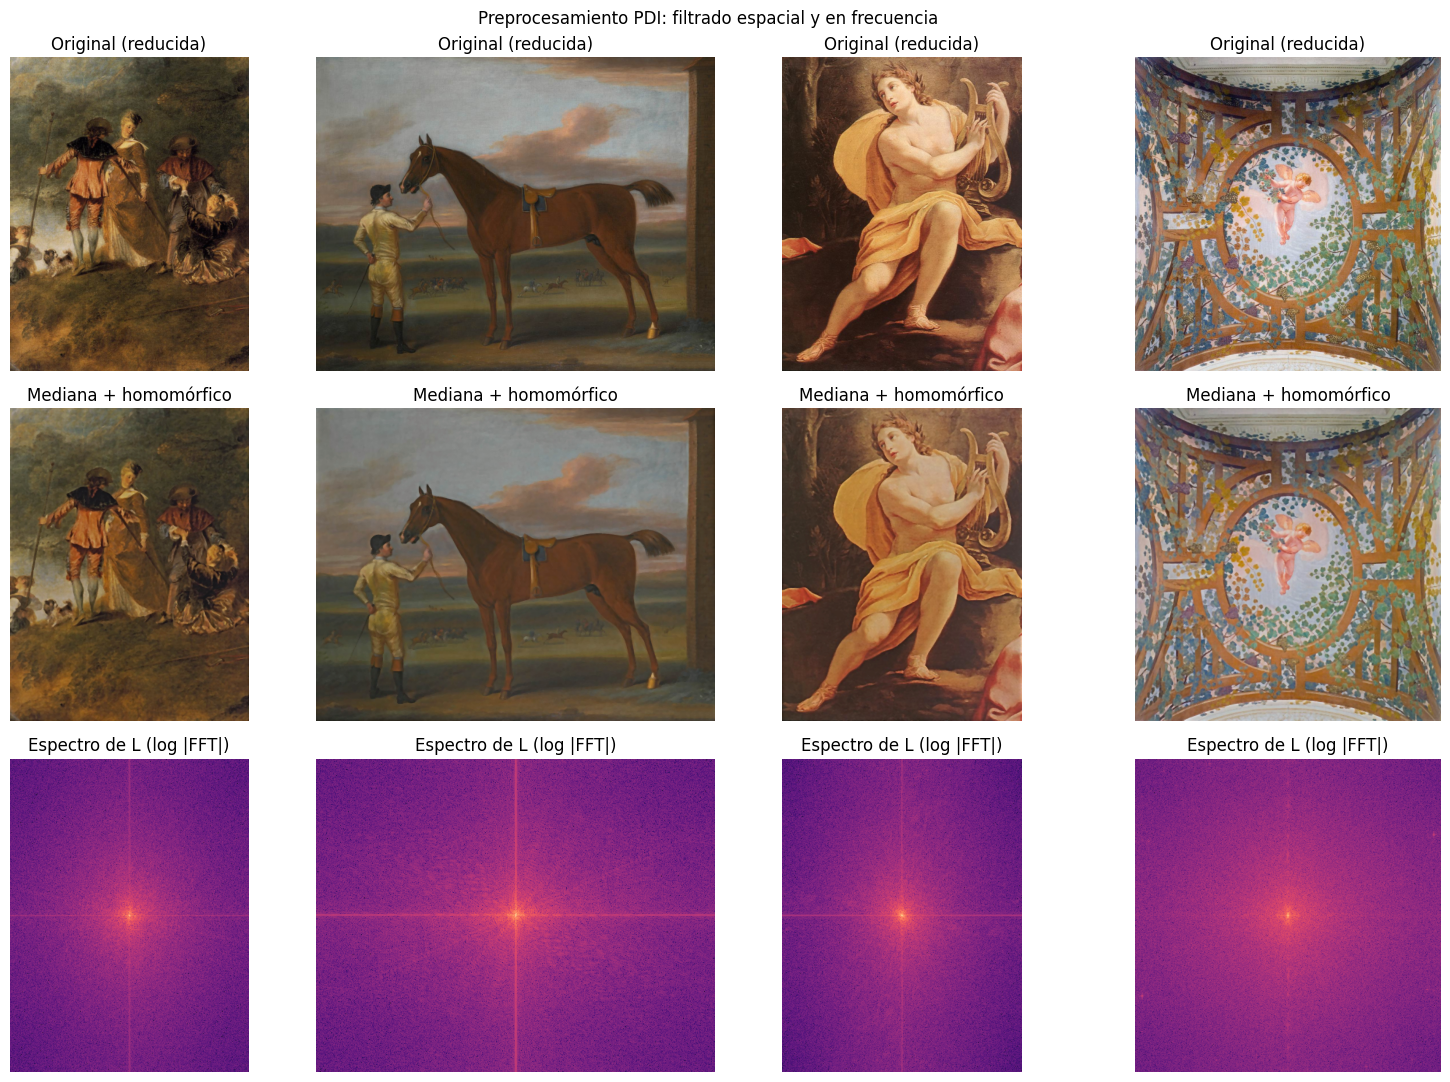

In [10]:
def fijar_semillas(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def dividir(muestras: list) -> dict:

    random.seed(SEED)
    reparto = {"entrenamiento": [], "validacion": [], "prueba": []}
    for clase in ["positivo", "negativo"]:
        idx = CLASES.index(clase)
        fotos = sorted((m for m in muestras if m[1] == idx), key=lambda m: str(m[0]))
        random.shuffle(fotos)
        n = len(fotos)
        n_train, n_val = round(0.8 * n), round(0.1 * n)
        reparto["entrenamiento"] += fotos[:n_train]
        reparto["validacion"] += fotos[n_train:n_train + n_val]
        reparto["prueba"] += fotos[n_train + n_val:]
    for k in reparto:
        reparto[k].sort(key=lambda t: (t[1], t[0].name))
    return reparto


class ObrasDataset(Dataset):

    def __init__(self, muestras, transform, filtros: bool):
        self.muestras = muestras
        self.transform = transform
        self.cache = [(preparar_para_cnn(cargar_imagen(Path(r).read_bytes(), str(r)), filtros), y) for r, y in muestras]

    def __len__(self):
        return len(self.cache)

    def __getitem__(self, i):
        img, y = self.cache[i]
        return self.transform(img), y


def calcular_media_std(ds_basico):

    suma, suma_cuad, n = torch.zeros(3), torch.zeros(3), 0
    for img, _ in DataLoader(ds_basico, batch_size=32, shuffle=False):
        suma += img.sum(dim=[0, 2, 3])
        suma_cuad += (img ** 2).sum(dim=[0, 2, 3])
        n += img.shape[0] * img.shape[2] * img.shape[3]
    media = suma / n
    return media, torch.sqrt(suma_cuad / n - media ** 2)


def preparar_conjuntos(reparto: dict, filtros: bool) -> dict:
    ds_train = ObrasDataset(reparto["entrenamiento"], transforms.ToTensor(), filtros)
    media, std = calcular_media_std(ds_train)
    ds_train.transform = transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5), transforms.RandomRotation(10),
        transforms.ToTensor(), transforms.Normalize(media.tolist(), std.tolist())])
    tf_eval = transforms.Compose([transforms.ToTensor(), transforms.Normalize(media.tolist(), std.tolist())])
    return {"train": ds_train, "val": ObrasDataset(reparto["validacion"], tf_eval, filtros),
            "test": ObrasDataset(reparto["prueba"], tf_eval, filtros), "media": media, "std": std, "filtros": filtros}


def crear_loaders(conj: dict):
    fijar_semillas()
    return (DataLoader(conj["train"], batch_size=BATCH_SIZE, shuffle=True),
            DataLoader(conj["val"], batch_size=BATCH_SIZE, shuffle=False),
            DataLoader(conj["test"], batch_size=BATCH_SIZE, shuffle=False))


if DATOS_LISTOS:
    reparto = dividir(fuente.etiquetadas())
    for k, v in reparto.items():
        print(f"{k:14s} positivo {sum(1 for _, y in v if y == 1):3d} | negativo {sum(1 for _, y in v if y == 0):3d}")

    print("Preparando imágenes (con y sin filtros PDI)…")
    conjuntos = {True: preparar_conjuntos(reparto, True)}
    if config.COMPARAR_FILTROS:
        conjuntos[False] = preparar_conjuntos(reparto, False)
    for f, c in conjuntos.items():
        print(f"{'con filtros' if f else 'sin filtros':12s} media {[round(v, 4) for v in c['media'].tolist()]} · std {[round(v, 4) for v in c['std'].tolist()]}")

    ejemplos = [r for r, _ in reparto["entrenamiento"][::max(1, len(reparto["entrenamiento"]) // 4)]][:4]
    fig, ax = plt.subplots(3, len(ejemplos), figsize=(4 * len(ejemplos), 11))
    for j, ruta in enumerate(ejemplos):
        img = cargar_imagen(Path(ruta).read_bytes())
        sin, con = filtrar_pdi(img, False), filtrar_pdi(img, True)
        ax[0, j].imshow(sin); ax[0, j].set_title("Original (reducida)")
        ax[1, j].imshow(con); ax[1, j].set_title("Mediana + homomórfico")
        l = cv2.cvtColor(sin, cv2.COLOR_RGB2LAB)[..., 0]
        ax[2, j].imshow(np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(l.astype(np.float32))))), cmap="magma")
        ax[2, j].set_title("Espectro de L (log |FFT|)")
        for a in ax[:, j]:
            a.axis("off")
    fig.suptitle("Preprocesamiento PDI: filtrado espacial y en frecuencia")
    plt.tight_layout(); plt.show()
else:
    print('Sin datos etiquetados suficientes: se omite la partición (añade imágenes a positivo/ y negativo/).')

### Arquitectura de la CNN

In [11]:
class CNN(nn.Module):

    def __init__(self, dropout: float = 0.0, img_size: int = 224):
        super().__init__()
        self.convs = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        lado = img_size // 8
        self.clasificador = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * lado * lado, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        return self.clasificador(self.convs(x))

    def embedding(self, x):
        return self.clasificador[2](self.clasificador[1](self.clasificador[0](self.convs(x))))


class CNNResNet18(nn.Module):
    def __init__(self, dropout: float = 0.5, preentrenada: bool = True):
        super().__init__()
        from torchvision import models
        base = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if preentrenada else None)
        self.convs = nn.Sequential(base.conv1, base.bn1, base.relu, base.maxpool,
                                   base.layer1, base.layer2, base.layer3, base.layer4, nn.AdaptiveAvgPool2d(1))
        self.clasificador = nn.Sequential(nn.Flatten(), nn.Linear(512, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, 2))
        if preentrenada:
            for capa in list(self.convs)[:6]:
                for p in capa.parameters():
                    p.requires_grad = False

    def forward(self, x):
        return self.clasificador(self.convs(x))

    def embedding(self, x):
        return self.clasificador[2](self.clasificador[1](self.clasificador[0](self.convs(x))))


def crear_cnn(arquitectura: str = "cnn3", dropout: float = 0.5, img_size: int = 224, preentrenada: bool = False) -> nn.Module:
    if arquitectura == "resnet18":
        return CNNResNet18(dropout=dropout, preentrenada=preentrenada)
    return CNN(dropout=dropout, img_size=img_size)


DESCRIPCION_ARQ = {
    "cnn3": "CNN 3 bloques conv (desde cero) + Dropout 0.5 + Weight Decay 1e-4 + Early Stopping (paciencia 5)",
    "resnet18": "ResNet-18 preentrenada (ImageNet, conv1–layer2 congeladas) + Dropout 0.5 + Weight Decay 1e-4 + Early Stopping (paciencia 5)",
}

### Funciones de entrenamiento y evaluación

In [12]:
def entrenar(modelo, train_loader, val_loader, epocas=30, lr=1e-3, weight_decay=0.0, paciencia=None, progreso=None):

    modelo = modelo.to(device)
    criterio = nn.CrossEntropyLoss()
    opt = optim.Adam(modelo.parameters(), lr=lr, weight_decay=weight_decay)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    mejor, mejores_pesos, sin_mejora, mejor_epoca = float("inf"), copy.deepcopy(modelo.state_dict()), 0, 0
    n_tr, n_va = len(train_loader.dataset), len(val_loader.dataset)

    for ep in range(1, epocas + 1):
        modelo.train()
        perdida, aciertos = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            out = modelo(x)
            loss = criterio(out, y)
            loss.backward()
            opt.step()
            perdida += loss.item() * x.size(0)
            aciertos += (out.argmax(1) == y).sum().item()
        tl, ta = perdida / n_tr, aciertos / n_tr

        modelo.eval()
        perdida, aciertos = 0.0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                out = modelo(x)
                perdida += criterio(out, y).item() * x.size(0)
                aciertos += (out.argmax(1) == y).sum().item()
        vl, va = perdida / n_va, aciertos / n_va
        for k, v in zip(hist, [tl, vl, ta, va]):
            hist[k].append(round(v, 4))

        if vl < mejor:
            mejor, mejores_pesos, sin_mejora, mejor_epoca = vl, copy.deepcopy(modelo.state_dict()), 0, ep
        else:
            sin_mejora += 1
        linea = f"Época {ep:02d} | train_loss {tl:.4f} acc {ta:.3f} | val_loss {vl:.4f} acc {va:.3f}"
        print(linea, flush=True)
        if progreso:
            progreso(linea)
        if paciencia is not None and sin_mejora >= paciencia:
            print(f"Early stopping en la época {ep} (mejor val_loss {mejor:.4f}, época {mejor_epoca})")
            break

    if paciencia is not None:
        modelo.load_state_dict(mejores_pesos)
    else:
        mejor_epoca = len(hist["train_loss"])
    return hist, mejor_epoca


def predecir_loader(modelo, loader):
    modelo.eval()
    pred, real = [], []
    with torch.no_grad():
        for x, y in loader:
            pred += modelo(x.to(device)).argmax(1).cpu().tolist()
            real += y.tolist()
    return real, pred


def evaluar(modelo, loader, nombre=None, mostrar=False):
    real, pred = predecir_loader(modelo, loader)
    m = {
        "accuracy": round(accuracy_score(real, pred), 3),
        "precision": round(precision_score(real, pred, pos_label=1, zero_division=0), 3),
        "recall": round(recall_score(real, pred, pos_label=1, zero_division=0), 3),
        "f1": round(f1_score(real, pred, pos_label=1, zero_division=0), 3),
        "matriz_confusion": confusion_matrix(real, pred, labels=[0, 1]).tolist(),
        "n": len(real),
    }
    if mostrar:
        print(f"=== {nombre} ===")
        for k in ("accuracy", "precision", "recall", "f1"):
            print(f"{k.capitalize():10s}: {m[k]}")
        print(classification_report(real, pred, target_names=CLASES, zero_division=0))
        ConfusionMatrixDisplay(np.array(m["matriz_confusion"]), display_labels=CLASES).plot(cmap="Blues")
        plt.title(f"Matriz de confusión — {nombre}")
        plt.show()
    return m


def graficar(hist, titulo):
    ep = range(1, len(hist["train_loss"]) + 1)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(ep, hist["train_loss"], label="Train"); plt.plot(ep, hist["val_loss"], label="Validación")
    plt.xlabel("Época"); plt.ylabel("Loss"); plt.title(f"{titulo} — Pérdida"); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(ep, hist["train_acc"], label="Train"); plt.plot(ep, hist["val_acc"], label="Validación")
    plt.xlabel("Época"); plt.ylabel("Accuracy"); plt.title(f"{titulo} — Accuracy"); plt.legend()
    plt.tight_layout(); plt.show()


def mostrar_errores(modelo, ds_test, titulo):
    real, pred = predecir_loader(modelo, DataLoader(ds_test, batch_size=BATCH_SIZE, shuffle=False))
    errores = [(ds_test.muestras[i][0], r, p) for i, (r, p) in enumerate(zip(real, pred)) if r != p]
    print(f"{titulo}: {len(errores)} errores de {len(ds_test)}")
    if not errores:
        return
    filas = (len(errores) + 5) // 6
    plt.figure(figsize=(18, 3.6 * filas))
    for k, (ruta, r, p) in enumerate(errores):
        plt.subplot(filas, 6, k + 1)
        with Image.open(ruta) as im:
            plt.imshow(im.convert("RGB"))
        plt.title(f"real: {CLASES[r]}\npred: {CLASES[p]}", fontsize=9)
        plt.axis("off")
    plt.show()

### Respaldo del modelo actual antes de reentrenar

In [13]:
METRICAS_ANTERIORES, RESPALDO_MODELOS = None, None
if DATOS_LISTOS and config.REENTRENAR and config.RUTA_CNN.exists():
    RESPALDO_MODELOS = config.DIR_MODELOS.parent / f"{config.DIR_MODELOS.name}_respaldo_{time.strftime('%Y%m%d_%H%M')}"
    shutil.copytree(config.DIR_MODELOS, RESPALDO_MODELOS)
    if config.RUTA_METRICAS.exists():
        METRICAS_ANTERIORES = json.loads(config.RUTA_METRICAS.read_text(encoding="utf-8"))
    print("Modelo actual respaldado en:", RESPALDO_MODELOS)
    print("Para restaurarlo: copia cnn_obras.pt, metricas_cnn.json y particion_cnn.json de esa carpeta a", config.DIR_MODELOS)
else:
    print("No se reentrena en esta ejecución (REENTRENAR = False): no hace falta respaldo.")

No se reentrena en esta ejecución (REENTRENAR = False): no hace falta respaldo.


### Entrenamiento con y sin filtrado PDI (se elige por pérdida de validación)

In [14]:
def guardar_modelo(modelo, conj, hist, mejor_epoca, metricas, reparto, extra=None) -> None:

    torch.save({"state_dict": {k: v.cpu() for k, v in modelo.state_dict().items()},
                "media": conj["media"].tolist(), "std": conj["std"].tolist(), "clases": CLASES,
                "img_size": IMG_SIZE, "dropout": config.DROPOUT, "filtros": conj["filtros"],
                "arquitectura": getattr(modelo, "arquitectura", "cnn3")}, config.RUTA_CNN)
    datos = {"modelo": DESCRIPCION_ARQ[getattr(modelo, "arquitectura", "cnn3")], "arquitectura": getattr(modelo, "arquitectura", "cnn3"),
             "filtros_pdi": conj["filtros"], "mejor_epoca": mejor_epoca, "prueba": metricas, "historial": hist,
             "particion": {k: len(v) for k, v in reparto.items()}, "fuente": fuente.reporte["origen"],
             "media": conj["media"].tolist(), "std": conj["std"].tolist(), "fecha": time.time()}
    datos.update(extra or {})
    config.RUTA_METRICAS.write_text(json.dumps(datos, ensure_ascii=False, indent=2), encoding="utf-8")
    config.RUTA_PARTICION.write_text(json.dumps(
        {"descripcion": "Partición usada para entrenar la CNN (nombre de archivo -> conjunto y clase)",
         "archivos": {Path(r).name: {"particion": k, "clase": CLASES[y]} for k, v in reparto.items() for r, y in v}},
        ensure_ascii=False, indent=1), encoding="utf-8")


def entrenar_modelo_b(conj: dict, progreso=None):

    train_loader, val_loader, test_loader = crear_loaders(conj)
    torch.manual_seed(SEED)
    arq = config.ARQUITECTURA
    modelo = crear_cnn(arq, dropout=config.DROPOUT, preentrenada=True)
    modelo.arquitectura = arq
    hist, mejor = entrenar(modelo, train_loader, val_loader, epocas=config.EPOCAS,
                           lr=config.LR_RESNET if arq == "resnet18" else config.LR,
                           weight_decay=config.WEIGHT_DECAY, paciencia=config.PACIENCIA, progreso=progreso)
    return modelo, hist, mejor, evaluar(modelo, test_loader), min(hist["val_loss"])


if DATOS_LISTOS:
    t0 = time.time()
    historiales, ablacion = {}, {}
    if config.REENTRENAR or not config.RUTA_CNN.exists():
        for filtros, conj in conjuntos.items():
            nombre = "con filtros PDI" if filtros else "sin filtros"
            print(f"\n--- Modelo B {nombre} ---")
            ablacion[filtros] = entrenar_modelo_b(conj)
            historiales[f"Modelo B {nombre}"] = ablacion[filtros][1]
        elegido = min(ablacion, key=lambda f: ablacion[f][4])
        modelo_reg, hist_reg, mejor_epoca, metricas_reg, _ = ablacion[elegido]
        conj_final = conjuntos[elegido]
        guardar_modelo(modelo_reg, conj_final, hist_reg, mejor_epoca, metricas_reg, reparto,
                       {"ablacion": {("con_filtros" if f else "sin_filtros"): {"val_loss": round(v[4], 4), "prueba": v[3]}
                                     for f, v in ablacion.items()}})
        print(f"\nElegido por validación: {'con' if elegido else 'sin'} filtros PDI · prueba: {metricas_reg}")
        if METRICAS_ANTERIORES:
            a, n = METRICAS_ANTERIORES, metricas_reg
            print(f"\nComparación en la MISMA partición de prueba ({n['n']} obras):")
            print(f"  anterior ({a.get('arquitectura', 'cnn3')}): val_loss {min(a['historial']['val_loss']):.4f} · "
                  f"accuracy {a['prueba']['accuracy']:.3f} · F1 {a['prueba']['f1']:.3f}")
            print(f"  nuevo    ({config.ARQUITECTURA}): val_loss {min(hist_reg['val_loss']):.4f} · "
                  f"accuracy {n['accuracy']:.3f} · F1 {n['f1']:.3f}")
            print(f"  Si el nuevo es peor, restaura la copia: {RESPALDO_MODELOS}")
    else:
        ckpt = torch.load(config.RUTA_CNN, map_location=device, weights_only=False)
        modelo_reg = crear_cnn(ckpt.get("arquitectura", "cnn3"), dropout=ckpt.get("dropout", config.DROPOUT)).to(device)
        modelo_reg.arquitectura = ckpt.get("arquitectura", "cnn3")
        modelo_reg.load_state_dict(ckpt["state_dict"])
        elegido = bool(ckpt.get("filtros", False))
        conj_final = conjuntos.get(elegido) or preparar_conjuntos(reparto, elegido)
        datos_m = json.loads(config.RUTA_METRICAS.read_text(encoding="utf-8"))
        hist_reg, mejor_epoca = datos_m["historial"], datos_m["mejor_epoca"]
        historiales["Modelo B (guardado)"] = hist_reg
        print("Se reutiliza el modelo entrenado:", config.RUTA_CNN)

    print(f"\nEntrenamiento terminado en {time.time() - t0:.0f} s")
else:
    print('Sin datos etiquetados suficientes: no se entrena la CNN. Si existe un modelo guardado en app_pdi/modelos, el sistema lo usará.')

Se reutiliza el modelo entrenado: /content/drive/MyDrive/Proyecto Final PDI VERSION 3/modelos_app/cnn_obras.pt

Entrenamiento terminado en 2 s


### Paleta cromática

In [15]:
_TONOS = [(15, "rojo"), (40, "naranja"), (65, "amarillo"), (150, "verde"), (195, "cian"),
          (255, "azul"), (290, "violeta"), (335, "magenta"), (360, "rojo")]


def nombre_color(rgb) -> str:
    r, g, b = [c / 255 for c in rgb]
    h, l, s = colorsys.rgb_to_hls(r, g, b)
    if l < 0.12:
        return "negro"
    if l > 0.92:
        return "blanco"
    if s < 0.15:
        return "gris oscuro" if l < 0.4 else ("gris claro" if l > 0.7 else "gris")
    grados = h * 360
    base = next(n for lim, n in _TONOS if grados <= lim)
    if base in ("naranja", "amarillo", "rojo") and s < 0.45:
        return "beige" if l > 0.65 else ("marrón" if l < 0.5 else "ocre")
    if base in ("naranja", "rojo") and l < 0.35 and s < 0.6:
        base = "marrón"
    if l < 0.3:
        return f"{base} oscuro"
    if l > 0.75:
        return f"{base} claro"
    return base


def _es_calido(rgb) -> bool:

    h, l, s = colorsys.rgb_to_hls(*[c / 255 for c in rgb])
    grados = h * 360
    return s >= 0.15 and (grados < 75 or grados > 320)


class ExtractorDePaleta:


    def __init__(self, n_colores: int = config.N_COLORES, lado: int = config.LADO_MUESTREO_PALETA):

        self.k = n_colores
        self.lado = lado

    def __call__(self, img_rgb: np.ndarray) -> dict:

        h, w = img_rgb.shape[:2]
        escala = min(1.0, self.lado / max(h, w))
        peq = cv2.resize(img_rgb, (max(1, int(w * escala)), max(1, int(h * escala))), interpolation=cv2.INTER_AREA)
        lab = cv2.cvtColor(peq, cv2.COLOR_RGB2LAB).reshape(-1, 3).astype(np.float32)

        k = int(min(self.k, max(1, len(np.unique(lab, axis=0)))))
        criterio = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.5)
        cv2.setRNGSeed(42)
        _, etiquetas, centros = cv2.kmeans(lab, k, None, criterio, 4, cv2.KMEANS_PP_CENTERS)
        conteos = np.bincount(etiquetas.ravel(), minlength=k).astype(np.float64)
        proporciones = conteos / conteos.sum()

        centros_rgb = cv2.cvtColor(centros.reshape(1, -1, 3).astype(np.uint8), cv2.COLOR_LAB2RGB).reshape(-1, 3)
        orden = np.argsort(-proporciones)
        colores = []
        for i in orden:
            if proporciones[i] <= 0:
                continue
            rgb = [int(v) for v in centros_rgb[i]]
            colores.append({
                "hex": "#{:02X}{:02X}{:02X}".format(*rgb),
                "rgb": rgb,
                "proporcion": round(float(proporciones[i]), 4),
                "nombre": nombre_color(rgb),
            })

        hsv = cv2.cvtColor(peq, cv2.COLOR_RGB2HSV)
        calidez = sum(c["proporcion"] for c in colores if _es_calido(c["rgb"]))
        return {
            "colores": colores,
            "brillo_medio": round(float(hsv[..., 2].mean() / 255), 3),
            "saturacion_media": round(float(hsv[..., 1].mean() / 255), 3),
            "proporcion_calida": round(float(calidez), 3),
        }

### Revisión de la detección facial
La neutralidad es donde se concentraban los errores. El flujo corregido, igual en entrenamiento, predicción y cámara, es:

1. **Primero se detecta el rostro, después se clasifica.** YuNet entrega la caja, 5 puntos faciales y un puntaje; solo se clasifican rostros con puntaje ≥ 0.60 en imágenes y ≥ 0.80 en la cámara, donde hay más ruido de movimiento.
   - **Sin rostro:** no se decide la neutralidad y se informa (`rostro_no_detectado`). Clasificar un recorte sin cara daría una probabilidad sin sentido.
   - **Con varios rostros:** cada uno se clasifica y se informa por separado. Como rostro principal se toma el de **mayor tamaño**, porque es el más cercano y el de mejor resolución, es decir, el más fiable.
   - **En la cámara:** se sigue al mismo rostro entre fotogramas (IoU ≥ 0.3), para no promediar personas distintas.
2. **Recorte cuadrado con relleno.** Antes, el recorte se cortaba contra el borde de la imagen y quedaba rectangular, y al llevarlo a 64×64 la cara se deformaba. Ahora el recorte es cuadrado (margen 1.15) y se rellena replicando el borde.
3. **Alineación.** El rostro se rota según el ángulo entre los ojos antes de recortar. Así una cabeza inclinada se ve igual que una derecha.
4. **Normalización idéntica en todos los flujos.** Toda imagen entra por `cargar_imagen` (orientación EXIF y RGB). El rostro se pasa a gris 64×64 con valores 0–255, que es lo que espera FER+. La CNN usa los mismos filtros con los que se entrenó, porque ese dato se guarda en el modelo.
5. **Decisión binaria con umbral justificado.** Antes, «neutral» era la emoción más probable entre 8, lo que era inconsistente: un rostro con P(neutral) = 0.45 podía salir neutral. Ahora se decide **neutral si P(neutral) ≥ τ**.
   - **τ = 0.5 por defecto**, por la regla de Bayes con costos iguales: es neutral si P(neutral) > P(no neutral).
   - **Calibración con fotos propias:** con ≥ 10 fotos por clase del equipo se calcula τ por el índice de Youden. Solo se acepta si el AUC es ≥ 0.6 y si mejora la exactitud balanceada frente a τ = 0.5.

### Análisis facial: detección, alineación, emoción, neutralidad y calificación del rostro

In [16]:
EMOCIONES = ["neutral", "felicidad", "sorpresa", "tristeza", "enojo", "asco", "miedo", "desprecio"]
EMOCIONES_ES = {
    "neutral": "Neutral", "felicidad": "Felicidad", "sorpresa": "Sorpresa", "tristeza": "Tristeza",
    "enojo": "Enojo", "asco": "Asco", "miedo": "Miedo", "desprecio": "Desprecio",
}
VALENCIA = {
    "felicidad": 1.0, "sorpresa": 0.3, "neutral": 0.0, "desprecio": -0.5,
    "miedo": -0.7, "tristeza": -0.8, "asco": -0.8, "enojo": -0.9,
}


VARIANTES_RECORTE = ("original", "corregido", "corregido_clahe")


def _softmax(z: np.ndarray) -> np.ndarray:

    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()


def clasificar_neutralidad(probabilidades: dict, umbral: float) -> dict:

    p = float(probabilidades.get("neutral", 0.0))
    clase = "neutral" if p >= umbral else "no_neutral"
    resto = {e: v for e, v in probabilidades.items() if e != "neutral"}
    return {
        "clase": clase,
        "etiqueta": "Neutral" if clase == "neutral" else "No neutral",
        "probabilidad_neutral": round(p, 4),
        "confianza": round(p if clase == "neutral" else 1 - p, 4),
        "umbral": round(float(umbral), 4),
        "margen": round(abs(p - umbral), 4),
        "emocion_no_neutral": max(resto, key=resto.get) if resto else None,
    }


class AnalizarGestosFaciales:

    def __init__(self, ruta_yunet, ruta_ferplus, umbral_neutralidad: float = 0.5, variante: str = "corregido"):

        self._lock = threading.Lock()
        self.umbral_neutralidad = float(umbral_neutralidad)
        self.variante = variante if variante in VARIANTES_RECORTE else "corregido"
        self.detector = None
        self.haar = None
        self.emociones = None
        self.tipo_detector = None
        self.errores = []

        try:
            if ruta_yunet.exists() and hasattr(cv2, "FaceDetectorYN"):
                self.detector = cv2.FaceDetectorYN.create(str(ruta_yunet), "", (320, 320), 0.6, 0.3, 5000)
                self.tipo_detector = "YuNet"
        except Exception as e:
            self.errores.append(f"YuNet no disponible: {e}")
        if self.detector is None:
            ruta_haar = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
            self.haar = cv2.CascadeClassifier(ruta_haar)
            self.tipo_detector = "Haar (respaldo)"

        try:
            if ruta_ferplus.exists():
                import onnxruntime as ort
                opciones = ort.SessionOptions()
                opciones.intra_op_num_threads = 2
                self.emociones = ort.InferenceSession(str(ruta_ferplus), opciones, providers=["CPUExecutionProvider"])
                self._entrada = self.emociones.get_inputs()[0].name
            else:
                self.errores.append(f"No existe {ruta_ferplus.name}. Ejecuta descargar_modelos.py.")
        except Exception as e:
            self.errores.append(f"FER+ no disponible: {e}")

    @property
    def disponible(self) -> bool:

        return self.emociones is not None

    def _detectar(self, bgr: np.ndarray) -> list[dict]:

        h, w = bgr.shape[:2]
        caras = []
        if self.detector is not None:
            self.detector.setInputSize((w, h))
            _, res = self.detector.detect(bgr)
            for f in (res if res is not None else []):
                x, y, bw, bh = [float(v) for v in f[:4]]
                pts = f[4:14].reshape(5, 2).astype(float)
                caras.append({"caja": [x, y, bw, bh], "score": float(f[14]), "puntos": pts})
        else:
            gris = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
            for (x, y, bw, bh) in self.haar.detectMultiScale(gris, 1.1, 5, minSize=(40, 40)):
                caras.append({"caja": [float(x), float(y), float(bw), float(bh)], "score": 0.9, "puntos": None})
        return caras

    @staticmethod
    def recorte_facial(gris: np.ndarray, caja, puntos=None, variante: str = "corregido", margen: float = 1.15) -> np.ndarray | None:

        x, y, bw, bh = caja
        lado = max(bw, bh) * margen
        cx, cy = x + bw / 2, y + bh / 2
        if variante == "original":
            h, w = gris.shape[:2]
            x0, y0 = int(max(0, cx - lado / 2)), int(max(0, cy - lado / 2))
            x1, y1 = int(min(w, cx + lado / 2)), int(min(h, cy + lado / 2))
            if x1 - x0 < 8 or y1 - y0 < 8:
                return None
            return cv2.resize(gris[y0:y1, x0:x1], (64, 64), interpolation=cv2.INTER_AREA).astype(np.float32)
        if lado < 8:
            return None
        img = gris
        if puntos is not None:
            ojo_d, ojo_i = np.asarray(puntos[0], float), np.asarray(puntos[1], float)
            angulo = float(np.degrees(np.arctan2(ojo_i[1] - ojo_d[1], ojo_i[0] - ojo_d[0])))
            if abs(angulo) > 1.0:
                m = cv2.getRotationMatrix2D((cx, cy), angulo, 1.0)
                img = cv2.warpAffine(gris, m, (gris.shape[1], gris.shape[0]), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
        pad = int(np.ceil(lado))
        ampliada = cv2.copyMakeBorder(img, pad, pad, pad, pad, cv2.BORDER_REPLICATE)
        x0, y0 = int(round(cx - lado / 2)) + pad, int(round(cy - lado / 2)) + pad
        n = int(round(lado))
        recorte = ampliada[y0:y0 + n, x0:x0 + n]
        if recorte.shape[0] < 8 or recorte.shape[1] < 8:
            return None
        recorte = cv2.resize(recorte, (64, 64), interpolation=cv2.INTER_AREA)
        if variante == "corregido_clahe":
            recorte = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4)).apply(recorte)
        return recorte.astype(np.float32)

    def _emocion(self, gris: np.ndarray, caja, puntos=None, variante: str | None = None) -> np.ndarray | None:

        if self.emociones is None:
            return None
        rec = self.recorte_facial(gris, caja, puntos, variante or self.variante)
        if rec is None:
            return None
        logits = self.emociones.run(None, {self._entrada: rec[None, None]})[0][0]
        return _softmax(logits)

    @staticmethod
    def _gestos(puntos, caja) -> dict:

        if puntos is None:
            return {}
        ojo_d, ojo_i, nariz, boca_d, boca_i = puntos
        dx, dy = ojo_i - ojo_d
        dist_ojos = float(np.hypot(dx, dy)) or 1.0
        inclinacion = float(np.degrees(np.arctan2(dy, dx)))
        centro_ojos = (ojo_d + ojo_i) / 2
        giro = float((nariz[0] - centro_ojos[0]) / dist_ojos)
        ancho_boca = float(np.hypot(*(boca_i - boca_d)) / dist_ojos)
        return {
            "inclinacion_cabeza_grados": round(inclinacion, 1),
            "giro_relativo": round(giro, 3),
            "ancho_boca_relativo": round(ancho_boca, 3),
            "mirando_al_frente": bool(abs(giro) < 0.25 and abs(inclinacion) < 20),
        }

    @staticmethod
    def calificar(gris: np.ndarray, caja_px, score: float, gestos: dict) -> dict:

        h, w = gris.shape[:2]
        x, y, bw, bh = caja_px
        x0, y0 = int(max(0, x)), int(max(0, y))
        x1, y1 = int(min(w, x + bw)), int(min(h, y + bh))
        recorte = gris[y0:y1, x0:x1]
        if recorte.size == 0:
            recorte = gris
        lado = cv2.resize(recorte, (96, 96), interpolation=cv2.INTER_AREA)
        nitidez = float(cv2.Laplacian(lado, cv2.CV_64F).var())
        brillo = float(lado.mean())
        comp = {
            "deteccion": float(np.clip(score, 0, 1)),
            "tamano": float(np.clip((bw / w) / 0.25, 0, 1)),
            "frontalidad": (float(np.clip(1 - abs(gestos["giro_relativo"]) / 0.35, 0, 1) *
                                  np.clip(1 - abs(gestos["inclinacion_cabeza_grados"]) / 30, 0, 1))
                            if gestos else 0.7),
            "nitidez": float(np.clip(nitidez / 150, 0, 1)),
            "iluminacion": float(np.clip(1 - abs(brillo - 128) / 128, 0, 1)),
        }
        pesos = {"deteccion": .30, "tamano": .20, "frontalidad": .20, "nitidez": .15, "iluminacion": .15}
        puntaje = round(100 * sum(comp[k] * pesos[k] for k in pesos), 1)
        nivel = "Excelente" if puntaje >= 80 else "Buena" if puntaje >= 60 else "Regular" if puntaje >= 40 else "Baja"
        return {"puntaje": puntaje, "nivel": nivel, "componentes": {k: round(v, 3) for k, v in comp.items()}}

    def __call__(self, img_rgb: np.ndarray, variante: str | None = None) -> dict:

        h, w = img_rgb.shape[:2]
        bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
        gris = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
        with self._lock:
            caras = self._detectar(bgr)
            detecciones = []
            for c in caras:
                x, y, bw, bh = c["caja"]
                probs = self._emocion(gris, c["caja"], c["puntos"], variante)
                gestos = self._gestos(c["puntos"], c["caja"])
                det = {
                    "caja": {"x": round(max(0, x) / w, 4), "y": round(max(0, y) / h, 4),
                             "w": round(min(bw, w - max(0, x)) / w, 4), "h": round(min(bh, h - max(0, y)) / h, 4)},
                    "score_deteccion": round(c["score"], 3),
                    "gestos": gestos,
                    "calificacion": self.calificar(gris, c["caja"], c["score"], gestos),
                }
                if c["puntos"] is not None:
                    det["puntos"] = [[round(px / w, 4), round(py / h, 4)] for px, py in c["puntos"]]
                if probs is not None:
                    idx = int(np.argmax(probs))
                    det["probabilidades"] = {EMOCIONES[i]: round(float(p), 4) for i, p in enumerate(probs)}
                    det["emocion"] = EMOCIONES[idx]
                    det["confianza"] = round(float(probs[idx]), 4)
                    det["neutralidad"] = clasificar_neutralidad(det["probabilidades"], self.umbral_neutralidad)
                detecciones.append(det)
        return {"estado": "ok" if detecciones else "sin_rostro", "detecciones": detecciones}

### Reglas de validación de resultados (sin rostro, varios rostros, seguimiento en la cámara)

In [17]:
ETIQUETAS_OBRA = config.NOMBRES_CLASES
DESCRIPCION_OBRA = {
    "positivo": "transmite una sensación agradable o serena",
    "negativo": "transmite una sensación inquietante o tensa",
}


def exc(tipo, mensaje, gravedad="aviso", modulo="ResultadoProceso"):
    return {"tipo": tipo, "gravedad": gravedad, "mensaje": mensaje, "modulo": modulo}


def nivel_calificacion(p: float) -> str:
    return "Excelente" if p >= 80 else "Buena" if p >= 60 else "Regular" if p >= 40 else "Baja"


def _iou(a: dict, b: dict) -> float:
    x0, y0 = max(a["x"], b["x"]), max(a["y"], b["y"])
    x1, y1 = min(a["x"] + a["w"], b["x"] + b["w"]), min(a["y"] + a["h"], b["y"] + b["h"])
    inter = max(0.0, x1 - x0) * max(0.0, y1 - y0)
    union = a["w"] * a["h"] + b["w"] * b["h"] - inter
    return inter / union if union > 0 else 0.0


class ResultadoProceso:

    def __init__(self, clases, umbral_neutralidad: float = 0.5):

        self.clases = list(clases)
        self.umbral_neutralidad = float(umbral_neutralidad)

    def procesar_obra(self, logits: torch.Tensor) -> tuple[dict, list]:

        probs = torch.softmax(logits, dim=1)[0].tolist()
        idx = int(np.argmax(probs))
        categoria = self.clases[idx]
        conf = float(probs[idx])
        revision = conf < config.UMBRAL_CONFIANZA_OBRA
        out = {
            "categoria": categoria,
            "etiqueta": ETIQUETAS_OBRA.get(categoria, categoria),
            "descripcion": DESCRIPCION_OBRA.get(categoria, ""),
            "confianza": round(conf, 4),
            "puntuaciones": {c: round(float(p), 4) for c, p in zip(self.clases, probs)},
            "logits": [round(float(v), 4) for v in logits[0].tolist()],
            "valencia": round(float(probs[self.clases.index("positivo")] - probs[self.clases.index("negativo")]), 4),
            "revision_requerida": revision,
            "umbral": config.UMBRAL_CONFIANZA_OBRA,
        }
        excepciones = []
        if revision:
            excepciones.append(exc(
                "fuera_de_rango",
                f"La CNN no está segura de la categoría de la obra ({conf:.0%} < umbral {config.UMBRAL_CONFIANZA_OBRA:.0%}). "
                "El resultado se muestra, pero requiere revisión.", "aviso", "ClasificadorDeObras"))
        return out, excepciones

    @staticmethod
    def validar_paleta(paleta: dict) -> list:

        errores = []
        colores = paleta.get("colores", [])
        suma = sum(c["proporcion"] for c in colores)
        if not colores:
            errores.append(exc("no_reconocido", "No se pudieron extraer colores de la obra.", "aviso", "ExtractorDePaleta"))
        elif abs(suma - 1) > 0.02:
            errores.append(exc("fuera_de_rango", f"Las proporciones de la paleta suman {suma:.2f} (se esperaba 1).", "aviso", "ExtractorDePaleta"))
        if any(not re.fullmatch(r"#[0-9A-F]{6}", c["hex"]) for c in colores):
            errores.append(exc("formato", "La paleta contiene códigos HEX inválidos.", "aviso", "ExtractorDePaleta"))
        return errores

    @staticmethod
    def validar_calidad(calidad: dict, que: str, modulo: str) -> list:

        out = []
        if calidad["brillo"] < config.BRILLO_MIN:
            out.append(exc("calidad_insuficiente",
                           f"La imagen de {que} está muy oscura (brillo {calidad['brillo']:.0f}/255). Mejora la iluminación.",
                           "aviso", modulo))
        elif calidad["brillo"] > config.BRILLO_MAX:
            out.append(exc("calidad_insuficiente",
                           f"La imagen de {que} está sobreexpuesta (brillo {calidad['brillo']:.0f}/255).", "aviso", modulo))
        if calidad["nitidez"] < config.NITIDEZ_MIN:
            out.append(exc("calidad_insuficiente",
                           f"La imagen de {que} está borrosa (nitidez {calidad['nitidez']:.0f}). Mantén la cámara estable.",
                           "aviso", modulo))
        return out

    @staticmethod
    def filtrar_detecciones(analisis: dict, previo: dict | None = None) -> tuple[dict | None, int]:

        validas = [d for d in analisis.get("detecciones", [])
                   if d["score_deteccion"] >= config.UMBRAL_CONFIANZA_ROSTRO and d["caja"]["w"] >= config.TAM_MIN_ROSTRO]
        if not validas:
            return None, 0
        if previo is not None:
            mejor = max(validas, key=lambda d: _iou(d["caja"], previo))
            if _iou(mejor["caja"], previo) >= 0.3:
                return mejor, len(validas)
        principal = max(validas, key=lambda d: d["caja"]["w"] * d["caja"]["h"])
        return principal, len(validas)

    def procesar_secuencia(self, frames: list[dict]) -> tuple[dict | None, list]:

        excepciones = []
        linea, probs_validas, principales, multiples = [], [], [], 0
        previo = None
        for f in frames:
            principal, n = self.filtrar_detecciones(f["analisis"], previo)
            if principal is not None:
                previo = principal["caja"]
            if n > 1:
                multiples += 1
            punto = {"t": f["t"], "rostro": principal is not None}
            if principal and "probabilidades" in principal:
                p = np.array([principal["probabilidades"][e] for e in EMOCIONES])
                probs_validas.append(p)
                principales.append((f, principal))
                punto.update({
                    "emocion": principal["emocion"],
                    "confianza": principal["confianza"],
                    "valencia": round(float(sum(p[i] * VALENCIA[e] for i, e in enumerate(EMOCIONES))), 4),
                    "p_neutral": round(float(principal["probabilidades"]["neutral"]), 4),
                })
            linea.append(punto)

        total = len(frames)
        con_rostro = len(probs_validas)
        if total and con_rostro == 0:
            excepciones.append(exc("rostro_no_detectado",
                                   "No se detectó ningún rostro. Ajusta la iluminación o la posición: la persona debe estar de frente y dentro del cuadro.",
                                   "error", "AnalizarGestosFaciales"))
            return None, excepciones
        if total and con_rostro / total < 0.5:
            excepciones.append(exc("rostro_no_detectado",
                                   f"El rostro solo se detectó en {con_rostro} de {total} fotogramas. Mantente frente a la cámara.",
                                   "aviso", "AnalizarGestosFaciales"))
        if multiples:
            excepciones.append(exc("multiples_rostros",
                                   f"Se detectó más de una persona en {multiples} fotograma(s); se siguió siempre al mismo rostro (el más cercano al inicio).",
                                   "aviso", "AnalizarGestosFaciales"))

        media = np.mean(probs_validas, axis=0)
        idx = int(np.argmax(media))
        emocion = EMOCIONES[idx]
        confianza = float(media[idx])
        if confianza < config.UMBRAL_EMOCION:
            excepciones.append(exc("fuera_de_rango",
                                   f"La expresión es ambigua: la emoción dominante ({EMOCIONES_ES[emocion]}) solo alcanza {confianza:.0%}.",
                                   "aviso", "AnalizarGestosFaciales"))

        f_rep, det_rep = max(principales, key=lambda fp: fp[1]["probabilidades"][emocion])
        gestos = [d["gestos"] for _, d in principales if d.get("gestos")]
        resumen_gestos = {}
        if gestos:
            for k in ("inclinacion_cabeza_grados", "giro_relativo", "ancho_boca_relativo"):
                resumen_gestos[k] = round(float(np.mean([g[k] for g in gestos])), 3)
            resumen_gestos["porcentaje_mirando_al_frente"] = round(float(np.mean([g["mirando_al_frente"] for g in gestos])), 3)

        valencia = float(sum(media[i] * VALENCIA[e] for i, e in enumerate(EMOCIONES)))
        puntajes = [d["calificacion"]["puntaje"] for _, d in principales if d.get("calificacion")]
        calificacion = None
        if puntajes:
            p_media = round(float(np.mean(puntajes)), 1)
            calificacion = {"puntaje": p_media, "minimo": round(float(np.min(puntajes)), 1),
                            "nivel": nivel_calificacion(p_media), "componentes": det_rep.get("calificacion", {}).get("componentes")}
        cambios = sum(1 for a, b in zip(principales, principales[1:]) if a[1]["emocion"] != b[1]["emocion"])
        probabilidades = {e: round(float(v), 4) for e, v in zip(EMOCIONES, media)}
        neutralidad = clasificar_neutralidad(probabilidades, self.umbral_neutralidad)
        neutralidad["fotogramas_neutrales"] = round(float(np.mean([pt["p_neutral"] >= self.umbral_neutralidad
                                                                    for pt in linea if "p_neutral" in pt])), 3)
        if neutralidad["margen"] < 0.1:
            excepciones.append(exc("fuera_de_rango",
                                   f"La decisión neutral / no neutral es dudosa: P(neutral) = {neutralidad['probabilidad_neutral']:.0%} "
                                   f"está muy cerca del umbral ({neutralidad['umbral']:.0%}).", "aviso", "AnalizarGestosFaciales"))
        rostro = {
            "emocion": emocion,
            "etiqueta": EMOCIONES_ES[emocion],
            "confianza": round(confianza, 4),
            "probabilidades": probabilidades,
            "neutralidad": neutralidad,
            "valencia": round(valencia, 4),
            "caja": det_rep["caja"],
            "puntos": det_rep.get("puntos"),
            "indice_frame": f_rep["indice"],
            "gestos": resumen_gestos,
            "calificacion": calificacion,
            "frames_analizados": total,
            "frames_con_rostro": con_rostro,
            "cambios_de_expresion": cambios,
            "linea_tiempo": linea,
        }
        return rostro, excepciones

    @staticmethod
    def procesar_rostros_imagen(analisis: dict, que: str) -> tuple[dict, list]:

        validas = [d for d in analisis.get("detecciones", [])
                   if d["score_deteccion"] >= config.UMBRAL_ROSTRO_OBRA and d["caja"]["w"] >= config.TAM_MIN_ROSTRO_OBRA]
        validas.sort(key=lambda d: d["caja"]["w"] * d["caja"]["h"], reverse=True)
        for i, d in enumerate(validas, 1):
            d["id"] = i
            if "emocion" in d:
                d["etiqueta"] = EMOCIONES_ES[d["emocion"]]
                d["valencia"] = round(float(sum(d["probabilidades"][e] * VALENCIA[e] for e in EMOCIONES)), 4)
        excepciones = []
        if not validas:
            excepciones.append(exc("rostro_no_detectado",
                                   f"No se detectó ningún rostro en {que}. Se muestran la clasificación de la CNN y la paleta, "
                                   "pero no hay emoción ni calificación facial que reportar.", "info", "AnalizarGestosFaciales"))
        out = {"estado": "ok" if validas else "sin_rostro", "n": len(validas), "detecciones": validas,
               "principal": validas[0] if validas else None}
        if validas and all("emocion" in d for d in validas):
            conteo = {}
            for d in validas:
                conteo[d["emocion"]] = conteo.get(d["emocion"], 0) + 1
            out["emocion_predominante"] = max(conteo, key=conteo.get)
            out["calificacion_media"] = round(float(np.mean([d["calificacion"]["puntaje"] for d in validas])), 1)
            out["neutralidad_principal"] = validas[0].get("neutralidad")
            out["n_neutrales"] = sum(1 for d in validas if d.get("neutralidad", {}).get("clase") == "neutral")
        if len(validas) > 1:
            excepciones.append(exc("multiples_rostros",
                                   f"Se detectaron {len(validas)} rostros en {que}: se clasifica cada uno por separado y el "
                                   "principal es el más grande.", "info", "AnalizarGestosFaciales"))
        return out, excepciones

    @staticmethod
    def coincidencia(obra: dict | None, rostro: dict | None):

        if not obra or not rostro:
            return None
        return round(1 - abs(obra["valencia"] - rostro["valencia"]) / 2, 4)

### Calibración del umbral de neutralidad con fotos del equipo

In [18]:
AUC_MINIMO = 0.6
ETIQUETAS_EVAL = ("neutral", "no_neutral")


def leer_calibracion() -> dict:

    try:
        cal = json.loads(config.RUTA_UMBRAL.read_text(encoding="utf-8"))
        if 0 < float(cal["umbral"]) < 1:
            return cal
    except (OSError, ValueError, KeyError):
        pass
    return {"umbral": config.UMBRAL_NEUTRALIDAD, "variante": "corregido", "origen": "por_defecto",
            "justificacion": "τ = 0.5: regla de decisión de Bayes con costos iguales (neutral si P(neutral) > P(no neutral)). "
                             "Captura fotos etiquetadas y calibra para ajustarlo a tu cámara e iluminación."}


def conteo_fotos() -> dict:
    return {e: (sum(1 for p in (config.DIR_ROSTROS_EVAL / e).glob("*") if p.suffix.lower() in config.EXTS_IMAGEN)
                if (config.DIR_ROSTROS_EVAL / e).is_dir() else 0) for e in ETIQUETAS_EVAL}


def guardar_foto(datos: bytes, etiqueta: str) -> dict:

    if etiqueta not in ETIQUETAS_EVAL:
        raise ErrorProceso("formato", "La etiqueta debe ser «neutral» o «no_neutral».", "error", "CalibracionNeutralidad")
    cargar_imagen(datos, "la foto de evaluación")
    destino = config.DIR_ROSTROS_EVAL / etiqueta
    destino.mkdir(parents=True, exist_ok=True)
    (destino / f"{etiqueta}_{time.strftime('%Y%m%d_%H%M%S')}_{hashlib.md5(datos).hexdigest()[:8]}.jpg").write_bytes(datos)
    return conteo_fotos()


def _p_neutral(gestos, img: np.ndarray, variante: str) -> float | None:

    h, w = img.shape[:2]
    e = min(1.0, config.LADO_MAX_DETECCION / max(h, w))
    if e < 1:
        img = cv2.resize(img, (int(w * e), int(h * e)), interpolation=cv2.INTER_AREA)
    dets = [d for d in gestos(img, variante=variante)["detecciones"] if d["score_deteccion"] >= config.UMBRAL_ROSTRO_OBRA]
    if not dets or "probabilidades" not in dets[0]:
        return None
    return max(dets, key=lambda d: d["caja"]["w"] * d["caja"]["h"])["probabilidades"]["neutral"]


def calibrar_neutralidad(gestos, guardar: bool = True) -> dict:

    conteo = conteo_fotos()
    salida = {"conteo": conteo, "suficientes": min(conteo.values()) >= config.MIN_FOTOS_CALIBRACION, "variantes": {}}
    if not salida["suficientes"]:
        salida["justificacion"] = (f"Se necesitan al menos {config.MIN_FOTOS_CALIBRACION} fotos por clase "
                                   f"(hay {conteo['neutral']} neutrales y {conteo['no_neutral']} no neutrales). Se mantiene τ = 0.5.")
        salida.update({"elegida": None, "umbral": leer_calibracion()["umbral"]})
        return salida

    imagenes = []
    for etiqueta in ETIQUETAS_EVAL:
        for p in sorted((config.DIR_ROSTROS_EVAL / etiqueta).glob("*")):
            if p.suffix.lower() in config.EXTS_IMAGEN:
                try:
                    imagenes.append((cargar_imagen(p.read_bytes(), p.name), 1 if etiqueta == "neutral" else 0))
                except ErrorProceso:
                    continue
    mejor = None
    for variante in ("original", "corregido", "corregido_clahe"):
        pares = [(_p_neutral(gestos, img, variante), y) for img, y in imagenes]
        validos = [(p, y) for p, y in pares if p is not None]
        m = {"tasa_deteccion": round(len(validos) / max(1, len(pares)), 3), "n_evaluadas": len(validos)}
        ys = np.array([y for _, y in validos])
        ps = np.array([p for p, _ in validos])
        if len(set(ys.tolist())) == 2:
            fpr, tpr, umbrales = roc_curve(ys, ps)
            k = int(np.argmax(tpr - fpr))
            tau = float(np.clip(umbrales[k], 0.05, 0.95))
            pred = (ps >= tau).astype(int)
            m.update({
                "auc": round(float(roc_auc_score(ys, ps)), 3),
                "umbral_youden": round(tau, 3),
                "balanced_acc_05": round(float(balanced_accuracy_score(ys, (ps >= 0.5).astype(int))), 3),
                "balanced_acc_youden": round(float(balanced_accuracy_score(ys, pred)), 3),
                "matriz_confusion_youden": confusion_matrix(ys, pred, labels=[1, 0]).tolist(),
                "curva": {"fpr": [round(float(v), 3) for v in fpr], "tpr": [round(float(v), 3) for v in tpr]},
            })
            if mejor is None or m["auc"] > salida["variantes"][mejor]["auc"]:
                mejor = variante
        salida["variantes"][variante] = m

    if mejor is None:
        salida.update({"elegida": None, "umbral": leer_calibracion()["umbral"],
                       "justificacion": "No se detectaron rostros de ambas clases; revisa las fotos de evaluación."})
        return salida
    v = salida["variantes"][mejor]
    if v["auc"] < AUC_MINIMO:
        salida.update({"elegida": None, "umbral": leer_calibracion()["umbral"], "rechazada": mejor,
                       "justificacion": (f"No se activó la calibración: el mejor AUC es {v['auc']:.2f} (< {AUC_MINIMO}), es decir, "
                                         "P(neutral) no distingue tus fotos neutrales de las no neutrales. Revisa que cada foto "
                                         "esté guardada con la etiqueta correcta y que las expresiones no neutrales sean claras.")})
        return salida
    usar_youden = v["balanced_acc_youden"] > v["balanced_acc_05"]
    tau = v["umbral_youden"] if usar_youden else config.UMBRAL_NEUTRALIDAD
    v["umbral_elegido"] = tau
    salida.update({
        "elegida": mejor, "umbral": tau, "curva": v["curva"],
        "justificacion": (f"Variante «{mejor}» (AUC {v['auc']:.2f}, {v['n_evaluadas']} fotos del equipo). " +
                          (f"τ = {tau:.2f} maximiza el índice de Youden: exactitud balanceada {v['balanced_acc_05']:.0%} "
                           f"con τ = 0.5 → {v['balanced_acc_youden']:.0%} con τ calibrado." if usar_youden else
                           f"Se mantiene τ = 0.5 porque el umbral de Youden no mejora la exactitud balanceada "
                           f"({v['balanced_acc_05']:.0%}).")),
    })
    if guardar:
        config.RUTA_UMBRAL.write_text(json.dumps({
            "umbral": tau, "variante": mejor, "origen": "calibrado", "fecha": time.time(),
            "justificacion": salida["justificacion"], "auc": v["auc"], "conteo": conteo,
            "metricas": {k: {kk: vv for kk, vv in m.items() if kk != "curva"} for k, m in salida["variantes"].items()},
        }, ensure_ascii=False, indent=1), encoding="utf-8")
    return salida

### Agrupamiento no supervisado (color, textura GLCM, bordes y características de la CNN)

In [19]:
def glcm_textura(gris: np.ndarray, niveles: int = 8) -> np.ndarray:

    q = (gris.astype(np.int32) * niveles // 256).clip(0, niveles - 1)
    i, j = np.indices((niveles, niveles))
    salida = []
    for a, b in ((q[:, :-1], q[:, 1:]), (q[:-1, :], q[1:, :])):
        m = np.bincount((a * niveles + b).ravel(), minlength=niveles * niveles).reshape(niveles, niveles).astype(np.float64)
        m = m + m.T
        p = m / max(m.sum(), 1)
        salida.append([(p * (i - j) ** 2).sum(), (p * np.abs(i - j)).sum(), (p / (1 + (i - j) ** 2)).sum(), np.sqrt((p ** 2).sum())])
    return np.mean(salida, axis=0)


def caracteristicas_pdi(img_rgb: np.ndarray) -> dict:

    peq = cv2.resize(img_rgb, (128, 128), interpolation=cv2.INTER_AREA)
    hsv = cv2.cvtColor(peq, cv2.COLOR_RGB2HSV)
    hist = cv2.calcHist([hsv], [0, 1, 2], None, [8, 3, 3], [0, 180, 0, 256, 0, 256]).ravel()
    hist = hist / max(hist.sum(), 1)
    gris = cv2.cvtColor(peq, cv2.COLOR_RGB2GRAY)
    gx, gy = cv2.Sobel(gris, cv2.CV_64F, 1, 0, ksize=3), cv2.Sobel(gris, cv2.CV_64F, 0, 1, ksize=3)
    bordes = np.array([np.sqrt(gx ** 2 + gy ** 2).mean() / 255, np.log1p(cv2.Laplacian(gris, cv2.CV_64F).var())])
    tonos = cv2.calcHist([hsv], [0], (hsv[..., 1] > 40).astype(np.uint8), [18], [0, 180]).ravel()
    return {"color": hist, "textura": glcm_textura(gris), "bordes": bordes,
            "resumen": {"brillo": float(hsv[..., 2].mean() / 255), "saturacion": float(hsv[..., 1].mean() / 255),
                        "tono_dominante": int(np.argmax(tonos) * 20 + 10) if tonos.sum() else None}}


def _miniatura(img_rgb: np.ndarray, lado: int = 120) -> str:

    h, w = img_rgb.shape[:2]
    e = lado / max(h, w)
    peq = cv2.resize(img_rgb, (max(1, int(w * e)), max(1, int(h * e))), interpolation=cv2.INTER_AREA)
    _, buf = cv2.imencode(".jpg", cv2.cvtColor(peq, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 80])
    return "data:image/jpeg;base64," + base64.b64encode(buf.tobytes()).decode()


def agrupar_imagenes(rutas, clasificador, pre, etiquetas=None, k_max: int = 6, miniaturas: bool = True) -> dict:

    bloques = {"color": [], "textura": [], "bordes": []}
    tensores, nombres, resumenes, imgs, validas, descartadas = [], [], [], [], [], []
    for i, ruta in enumerate(rutas):
        try:
            img = cargar_imagen(open(ruta, "rb").read(), str(ruta))
        except (ErrorProceso, OSError) as e:
            descartadas.append({"archivo": str(ruta), "motivo": getattr(e, "mensaje", str(e))})
            continue
        c = caracteristicas_pdi(img)
        for k in bloques:
            bloques[k].append(c[k])
        resumenes.append(c["resumen"])
        tensores.append(pre(img)[0])
        nombres.append(getattr(ruta, "name", str(ruta)))
        imgs.append(np.asarray(preparar_para_cnn(img, False, 160)) if miniaturas else None)
        validas.append(i)
    if len(nombres) < 6:
        raise ErrorProceso("sin_datos", f"Se necesitan al menos 6 imágenes legibles para agrupar (hay {len(nombres)}).",
                           "error", "AgrupamientoNoSupervisado")
    lote = torch.stack(tensores)
    emb = np.concatenate([clasificador.embeddings(lote[i:i + 64]) for i in range(0, len(lote), 64)])
    p_pos = np.concatenate([torch.softmax(clasificador.predecir(lote[i:i + 64]), 1)[:, clasificador.clases.index("positivo")].numpy()
                            for i in range(0, len(lote), 64)])
    matrices = [np.asarray(bloques["color"]), np.asarray(bloques["textura"]), np.asarray(bloques["bordes"]), emb]
    X = np.hstack([StandardScaler().fit_transform(m) / np.sqrt(m.shape[1]) for m in matrices])
    X = np.nan_to_num(X)
    n_comp = int(min(20, X.shape[0] - 1, X.shape[1]))
    pca = PCA(n_components=n_comp, random_state=config.SEED).fit(X)
    Z = pca.transform(X)
    siluetas, modelos = {}, {}
    for k in range(2, int(min(k_max, len(nombres) - 1)) + 1):
        km = KMeans(n_clusters=k, n_init=10, random_state=config.SEED).fit(Z)
        siluetas[k] = float(silhouette_score(Z, km.labels_))
        modelos[k] = km
    k = max(siluetas, key=siluetas.get)
    km = modelos[k]
    grupos = []
    for g in range(k):
        idx = np.where(km.labels_ == g)[0]
        dist = np.linalg.norm(Z[idx] - km.cluster_centers_[g], axis=1)
        cercanas = idx[np.argsort(dist)[:6]]
        tonos = [resumenes[i]["tono_dominante"] for i in idx if resumenes[i]["tono_dominante"] is not None]
        grupos.append({
            "id": g + 1, "n": int(len(idx)),
            "p_positivo_medio": round(float(p_pos[idx].mean()), 3),
            "brillo": round(float(np.mean([resumenes[i]["brillo"] for i in idx])), 3),
            "saturacion": round(float(np.mean([resumenes[i]["saturacion"] for i in idx])), 3),
            "tono_dominante": int(np.median(tonos)) if tonos else None,
            "ejemplos": [{"nombre": nombres[i], "img": _miniatura(imgs[i])} for i in cercanas] if miniaturas else
                        [{"nombre": nombres[i]} for i in cercanas],
        })
    salida = {
        "k": int(k), "silueta": round(siluetas[k], 3), "silueta_por_k": {str(a): round(b, 3) for a, b in siluetas.items()},
        "varianza_pca": round(float(pca.explained_variance_ratio_[:2].sum()), 3), "n": len(nombres),
        "puntos": [{"nombre": nombres[i], "x": round(float(Z[i, 0]), 3), "y": round(float(Z[i, 1]), 3),
                    "grupo": int(km.labels_[i]) + 1, "p_positivo": round(float(p_pos[i]), 3)} for i in range(len(nombres))],
        "grupos": grupos, "descartadas": descartadas, "ari": None,
    }
    if etiquetas is not None:
        reales = [etiquetas[i] for i in validas]
        salida["ari"] = round(float(adjusted_rand_score(reales, km.labels_)), 3)
        salida["ari_k2"] = round(float(adjusted_rand_score(reales, modelos[2].labels_)), 3) if 2 in modelos else None
        for g in grupos:
            idx = np.where(km.labels_ == g["id"] - 1)[0]
            g["proporcion_positivas_reales"] = round(float(np.mean([reales[i] for i in idx])), 3)
    return salida

## 4. Predicción
`Sistema` reúne todos los componentes. `predecir_imagen` recibe una imagen nueva (ruta o bytes) y devuelve:

- la decisión **neutral / no neutral** de cada rostro, con su probabilidad;
- la **categoría de la obra** según la CNN, si hay un modelo entrenado.

### Clasificador de obras con Grad-CAM

In [20]:
class ClasificadorDeObras:

    def __init__(self, ruta_pesos: Path):

        self.filtros = False
        self.disponible = False
        self.error = None
        self.clases = ["negativo", "positivo"]
        self.media = None
        self.std = None
        self.modelo = None
        self._lock = threading.Lock()
        try:
            ckpt = torch.load(ruta_pesos, map_location="cpu", weights_only=False)
            self.arquitectura = ckpt.get("arquitectura", "cnn3")
            self.modelo = crear_cnn(self.arquitectura, dropout=ckpt.get("dropout", 0.5), img_size=ckpt.get("img_size", 224))
            self.modelo.load_state_dict(ckpt["state_dict"])
            self.modelo.eval()
            self.clases = ckpt.get("clases", self.clases)
            self.media = ckpt.get("media")
            self.std = ckpt.get("std")
            self.filtros = bool(ckpt.get("filtros", False))
            self.disponible = True
        except FileNotFoundError:
            self.error = ("Todavía no hay una CNN entrenada, así que la obra no se clasifica como positiva o negativa. "
                          "Carga las imágenes etiquetadas y pulsa «Reentrenar CNN» en la interfaz (o vuelve a ejecutar el notebook).")
        except Exception as e:
            self.error = f"No se pudo cargar la CNN: {e}"

    def predecir(self, tensor: torch.Tensor) -> torch.Tensor:
        with self._lock, torch.no_grad():
            return self.modelo(tensor)

    def embeddings(self, tensor: torch.Tensor) -> np.ndarray:
        with self._lock, torch.no_grad():
            return self.modelo.embedding(tensor).cpu().numpy()

    def gradcam(self, tensor: torch.Tensor, clase: int) -> np.ndarray:

        convs = self.modelo.convs
        with self._lock, torch.enable_grad():
            a = convs[:8](tensor)
            a.retain_grad()
            out = self.modelo.clasificador(convs[8](a))
            grad = torch.autograd.grad(out[0, clase], a)[0][0]
            pesos = grad.mean(dim=(1, 2))
            cam = torch.relu((pesos[:, None, None] * a[0]).sum(0)).detach().numpy()
        cam = cv2.resize(cam, (tensor.shape[3], tensor.shape[2]))
        cam = cv2.GaussianBlur(cam, (0, 0), 6)
        if cam.max() > 0:
            cam = (cam - cam.min()) / (cam.max() - cam.min())
        return cam.astype(np.float32)


def cam_a_overlay(img_rgb: np.ndarray, cam: np.ndarray, alpha: float = 0.45) -> str:

    h, w = img_rgb.shape[:2]
    escala = min(1.0, 640 / max(h, w))
    base = cv2.resize(img_rgb, (int(w * escala), int(h * escala)), interpolation=cv2.INTER_AREA)
    mapa = cv2.resize(cam, (base.shape[1], base.shape[0]))
    color = cv2.applyColorMap((mapa * 255).astype(np.uint8), cv2.COLORMAP_JET)
    color = cv2.cvtColor(color, cv2.COLOR_BGR2RGB)
    mezcla = (base * (1 - alpha) + color * alpha).astype(np.uint8)
    ok, buf = cv2.imencode(".jpg", cv2.cvtColor(mezcla, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 85])
    return "data:image/jpeg;base64," + base64.b64encode(buf.tobytes()).decode()


def regiones_desde_cam(cam: np.ndarray, max_regiones: int = 2, umbral: float = 0.6) -> list[dict]:

    h, w = cam.shape
    for u in (umbral, 0.72, 0.84):
        mascara = (cam >= u).astype(np.uint8)
        if mascara.mean() < 0.45:
            break
    n, _, stats, _ = cv2.connectedComponentsWithStats(mascara, connectivity=8)
    cajas = []
    for i in range(1, n):
        x, y, bw, bh, area = stats[i]
        if area < 0.01 * h * w:
            continue
        intensidad = float(cam[y:y + bh, x:x + bw].mean())
        cajas.append({"x": float(x / w), "y": float(y / h), "w": float(bw / w), "h": float(bh / h), "intensidad": intensidad, "area": int(area)})
    cajas.sort(key=lambda c: c["area"] * c["intensidad"], reverse=True)
    out = []
    for i, c in enumerate(cajas[:max_regiones]):
        out.append({
            "x": round(c["x"], 4), "y": round(c["y"], 4), "w": round(c["w"], 4), "h": round(c["h"], 4),
            "etiqueta": "Zona de mayor influencia" if i == 0 else "Zona secundaria",
            "confianza": round(c["intensidad"], 3),
        })
    return out

### Integración del sistema

In [21]:
def _data_url(img_rgb: np.ndarray, lado_max: int = 640) -> str:

    h, w = img_rgb.shape[:2]
    e = min(1.0, lado_max / max(h, w))
    peq = cv2.resize(img_rgb, (int(w * e), int(h * e)), interpolation=cv2.INTER_AREA) if e < 1 else img_rgb
    _, buf = cv2.imencode(".jpg", cv2.cvtColor(peq, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 85])
    return "data:image/jpeg;base64," + base64.b64encode(buf.tobytes()).decode()


def nivel(c):

    return "alta" if c >= 0.7 else "media" if c >= 0.4 else "baja"


class Sistema:

    def __init__(self, fuente):

        self.calibracion = leer_calibracion()
        self.clasificador = ClasificadorDeObras(config.RUTA_CNN)
        self.pre = PreprocesamientoImagen(self.clasificador.media, self.clasificador.std, filtros=self.clasificador.filtros)
        self.paleta = ExtractorDePaleta()
        self.gestos = AnalizarGestosFaciales(config.RUTA_YUNET, config.RUTA_FERPLUS,
                                             self.calibracion["umbral"], self.calibracion["variante"])
        self.resultado = ResultadoProceso(self.clasificador.clases, self.calibracion["umbral"])
        self.dataset = fuente

    def recargar_cnn(self) -> None:
        nuevo = ClasificadorDeObras(config.RUTA_CNN)
        self.pre = PreprocesamientoImagen(nuevo.media, nuevo.std, filtros=nuevo.filtros)
        self.clasificador = nuevo
        self.dataset.particion = self.dataset._cargar_particion()

    def aplicar_calibracion(self, cal: dict) -> None:

        self.calibracion = cal
        self.gestos.umbral_neutralidad = cal["umbral"]
        self.gestos.variante = cal["variante"]
        self.resultado.umbral_neutralidad = cal["umbral"]

    def estado(self) -> dict:
        return {
            "cnn": {"disponible": self.clasificador.disponible, "error": self.clasificador.error,
                    "filtros": self.clasificador.filtros,
                    "media": self.pre.media.round(4).tolist(), "std": self.pre.std.round(4).tolist()},
            "neutralidad": {k: v for k, v in self.calibracion.items() if k != "curva"},
            "rostro": {"detector": self.gestos.tipo_detector, "emociones": self.gestos.disponible,
                       "errores": self.gestos.errores},
            "umbrales": {
                "obra": config.UMBRAL_CONFIANZA_OBRA, "rostro": config.UMBRAL_CONFIANZA_ROSTRO,
                "emocion": config.UMBRAL_EMOCION, "tam_min_rostro": config.TAM_MIN_ROSTRO,
            },
        }

    def analizar_frame(self, datos: bytes) -> dict:

        img = cargar_imagen(datos, "fotograma")
        analisis = self.gestos(img)
        principal, n = self.resultado.filtrar_detecciones(analisis)
        cal = medir_calidad(img)
        return {
            "estado": "ok" if principal else "sin_rostro",
            "rostros": n,
            "principal": principal,
            "detecciones": analisis["detecciones"],
            "calidad": cal,
            "excepciones": self.resultado.validar_calidad(cal, "la cámara", "CapturaDeFrame") if principal is None else [],
        }

    def _rostros_en_imagen(self, img: np.ndarray, que: str, excepciones: list, tiempos: dict) -> dict:

        t0 = time.perf_counter()
        h, w = img.shape[:2]
        e = min(1.0, config.LADO_MAX_DETECCION / max(h, w))
        peq = cv2.resize(img, (int(w * e), int(h * e)), interpolation=cv2.INTER_AREA) if e < 1 else img
        rostros, exc_r = self.resultado.procesar_rostros_imagen(self.gestos(peq), que)
        excepciones += exc_r
        tiempos["rostros_obra"] = round((time.perf_counter() - t0) * 1000, 1)
        return rostros

    def _analizar_obra(self, datos: bytes, excepciones: list, tiempos: dict, que: str = "la obra"):

        t0 = time.perf_counter()
        img = cargar_imagen(datos, que)
        tiempos["image_loader"] = round((time.perf_counter() - t0) * 1000, 1)
        calidad = medir_calidad(img)
        excepciones += self.resultado.validar_calidad(calidad, que, "ImageLoader")

        obra = {"dimensiones": {"ancho": calidad["ancho"], "alto": calidad["alto"]}, "calidad": calidad}
        if self.gestos.disponible:
            obra["rostros"] = self._rostros_en_imagen(img, que, excepciones, tiempos)

        t0 = time.perf_counter()
        paleta = self.paleta(img)
        tiempos["paleta"] = round((time.perf_counter() - t0) * 1000, 1)
        excepciones += self.resultado.validar_paleta(paleta)
        obra["paleta"] = paleta

        if not self.clasificador.disponible:
            excepciones.append(exc("sin_modelo", self.clasificador.error or "La CNN no está disponible.", "aviso", "ClasificadorDeObras"))
            return obra
        t0 = time.perf_counter()
        tensor = self.pre(img)
        tiempos["preprocesamiento"] = round((time.perf_counter() - t0) * 1000, 1)
        t0 = time.perf_counter()
        logits = self.clasificador.predecir(tensor)
        tiempos["cnn"] = round((time.perf_counter() - t0) * 1000, 1)
        info, exc_obra = self.resultado.procesar_obra(logits)
        excepciones += exc_obra
        obra.update(info)
        obra["tensor"] = {"forma": list(tensor.shape), "tipo": str(tensor.dtype).replace("torch.", "")}

        t0 = time.perf_counter()
        cam = self.clasificador.gradcam(tensor, self.clasificador.clases.index(info["categoria"]))
        obra["gradcam"] = cam_a_overlay(img, cam)
        obra["regiones"] = regiones_desde_cam(cam)
        tiempos["gradcam"] = round((time.perf_counter() - t0) * 1000, 1)
        return obra

    def _analizar_frames(self, frames: list[tuple[bytes, float]], excepciones: list, tiempos: dict):
        t0 = time.perf_counter()
        procesados, imagenes, ilegibles = [], [], 0
        for i, (datos, t) in enumerate(frames[: config.MAX_FRAMES]):
            try:
                img = cargar_imagen(datos, f"fotograma {i + 1}")
            except ErrorProceso:
                ilegibles += 1
                continue
            imagenes.append(img)
            procesados.append({"t": t, "indice": len(imagenes) - 1, "analisis": self.gestos(img), "calidad": medir_calidad(img)})
        tiempos["gestos"] = round((time.perf_counter() - t0) * 1000, 1)
        if ilegibles:
            excepciones.append(exc("formato", f"{ilegibles} fotograma(s) no se pudieron leer y se descartaron.", "aviso", "CapturaDeFrame"))
        if not procesados:
            excepciones.append(exc("servidor", "No llegó ningún fotograma válido de la cámara.", "error", "CapturaDeFrame"))
            return None
        if not self.gestos.disponible:
            excepciones.append(exc("servidor", "El reconocedor de emociones no está disponible. " + " ".join(self.gestos.errores),
                                   "error", "AnalizarGestosFaciales"))
            return None

        rostro, exc_r = self.resultado.procesar_secuencia(procesados)
        excepciones += exc_r
        brillo = float(np.mean([p["calidad"]["brillo"] for p in procesados]))
        nitidez = float(np.median([p["calidad"]["nitidez"] for p in procesados]))
        excepciones += self.resultado.validar_calidad({"brillo": brillo, "nitidez": nitidez}, "la cámara", "CapturaDeFrame")
        if rostro is None:
            return {"frame": _data_url(imagenes[len(imagenes) // 2]), "sin_rostro": True,
                    "frames_analizados": len(procesados), "frames_con_rostro": 0}
        rostro["frame"] = _data_url(imagenes[rostro.pop("indice_frame")])
        rostro["calidad"] = {"brillo": round(brillo, 1), "nitidez": round(nitidez, 1)}
        return rostro

    def analizar(self, obra_bytes: bytes | None, frames: list[tuple[bytes, float]], modo: str = "visitante",
                 que: str = "la obra") -> dict:

        t_total = time.perf_counter()
        excepciones, tiempos = [], {}
        obra = rostro = None

        if obra_bytes is not None:
            try:
                obra = self._analizar_obra(obra_bytes, excepciones, tiempos, que)
            except ErrorProceso as e:
                excepciones.append(e.a_dict())
        if frames:
            rostro = self._analizar_frames(frames, excepciones, tiempos)

        if modo == "dataset":
            return self._cerrar_dataset(obra, excepciones, tiempos, t_total, que)

        if obra_bytes is None or not frames:
            falta = "el rostro (cámara)" if obra_bytes is not None else "la obra"
            excepciones.append(exc("entrada_incompleta",
                                   f"Falta {falta}. Para calcular la coincidencia emocional se necesitan ambos.", "aviso", "Integración"))

        rostro_valido = rostro if rostro and not rostro.get("sin_rostro") else None
        obra_valida = obra if obra and "categoria" in obra else None
        coincidencia = self.resultado.coincidencia(obra_valida, rostro_valido)

        if obra_valida and rostro_valido:
            texto = (f"La obra se clasificó como {obra_valida['etiqueta'].lower()} ({obra_valida['confianza']:.0%}): "
                     f"{obra_valida['descripcion']}. El visitante expresó principalmente {rostro_valido['etiqueta'].lower()} "
                     f"({rostro_valido['confianza']:.0%}). La coincidencia emocional es {nivel(coincidencia)} ({coincidencia:.0%}).")
        elif obra_valida:
            texto = f"La obra se clasificó como {obra_valida['etiqueta'].lower()} ({obra_valida['confianza']:.0%}). Falta el rostro para calcular la coincidencia."
        elif rostro_valido:
            texto = f"El visitante expresó principalmente {rostro_valido['etiqueta'].lower()} ({rostro_valido['confianza']:.0%}). Falta la obra para calcular la coincidencia."
        else:
            texto = "No se obtuvieron resultados válidos con las imágenes enviadas."

        hay_error = any(e["gravedad"] == "error" for e in excepciones)
        estado = "ok" if (obra_valida or rostro_valido) and not hay_error else ("parcial" if (obra_valida or rostro_valido) else "error")
        tiempos["total"] = round((time.perf_counter() - t_total) * 1000, 1)
        return {
            "modo": "visitante",
            "estado": estado,
            "obra": obra,
            "rostro": rostro,
            "coincidencia": coincidencia,
            "nivel_coincidencia": nivel(coincidencia) if coincidencia is not None else None,
            "interpretacion": texto,
            "excepciones": excepciones,
            "tiempos_ms": tiempos,
        }

    def _cerrar_dataset(self, obra, excepciones, tiempos, t_total, que):
        obra_valida = obra if obra and "categoria" in obra else None
        rostros = (obra or {}).get("rostros") or {}
        principal = rostros.get("principal")
        coherencia = None
        partes = []
        if obra_valida:
            partes.append(f"La CNN clasificó {que} como {obra_valida['etiqueta'].lower()} ({obra_valida['confianza']:.0%}).")
        if principal and "emocion" in principal:
            n = rostros["n"]
            neu = principal.get("neutralidad") or {}
            partes.append(f"Se detect{'ó 1 rostro' if n == 1 else f'aron {n} rostros'}; el principal es "
                          f"{neu.get('etiqueta', '—').lower()} ({neu.get('confianza', 0):.0%}), emoción más probable "
                          f"{principal['etiqueta'].lower()} ({principal['confianza']:.0%}), calificación "
                          f"{principal['calificacion']['puntaje']:.0f}/100 ({principal['calificacion']['nivel'].lower()}).")
            if obra_valida:
                coherencia = round(1 - abs(obra_valida["valencia"] - principal["valencia"]) / 2, 4)
                partes.append(f"Coherencia entre la categoría de la obra y la expresión del rostro: {nivel(coherencia)} ({coherencia:.0%}).")
        elif obra is not None and rostros:
            partes.append("No se detectaron rostros en la imagen.")
        texto = " ".join(partes) or "No se obtuvieron resultados válidos con la imagen enviada."
        hay_error = any(e["gravedad"] == "error" for e in excepciones)
        estado = "error" if not obra else ("parcial" if hay_error else "ok")
        tiempos["total"] = round((time.perf_counter() - t_total) * 1000, 1)
        return {
            "modo": "dataset",
            "estado": estado,
            "obra": obra,
            "rostro": None,
            "coincidencia": None,
            "nivel_coincidencia": None,
            "coherencia": coherencia,
            "nivel_coherencia": nivel(coherencia) if coherencia is not None else None,
            "interpretacion": texto,
            "excepciones": excepciones,
            "tiempos_ms": tiempos,
        }

    def analizar_dataset(self, nombre: str) -> dict:

        datos = self.dataset.leer(nombre)
        res = self.analizar(datos, [], modo="dataset", que="la imagen del dataset")
        info = self.dataset.info_imagen(nombre)
        res["dataset"] = info
        if info["cnn"]:
            parte = {"entrenamiento": "entrenamiento", "validacion": "validación", "prueba": "prueba"}[info["cnn"]["particion"]]
            gravedad = "info" if info["cnn"]["particion"] == "prueba" else "aviso"
            res["excepciones"].append(exc(
                "imagen_conocida",
                f"Esta imagen formó parte del conjunto de {parte} de la CNN (etiqueta real: {info['cnn']['clase']}). "
                + ("Su predicción no es una evaluación independiente." if gravedad == "aviso" else "Sirve como evaluación independiente."),
                gravedad, "ClasificadorDeObras"))
        return res

    def predecir(self, datos: bytes, nombre: str = "la imagen") -> dict:

        res = self.analizar(datos, [], modo="dataset", que=nombre)
        obra = res.get("obra") or {}
        rostros = obra.get("rostros") or {"n": 0, "detecciones": [], "principal": None}
        principal = rostros.get("principal")
        neu = principal.get("neutralidad") if principal else None
        if obra.get("categoria"):
            pred_obra = {"clase": obra["categoria"], "etiqueta": obra["etiqueta"], "probabilidad": obra["confianza"],
                         "revision_requerida": obra["revision_requerida"]}
        else:
            pred_obra = None
        if not obra:
            estado, mensaje = "error", "La imagen no se pudo analizar."
        elif not rostros["n"]:
            estado, mensaje = "sin_rostro", "No se detectó ningún rostro: no se puede decidir si la expresión es neutral."
        else:
            estado = "ok"
            mensaje = (f"Rostro principal: {neu['etiqueta']} con {neu['confianza']:.0%} de confianza "
                       f"(P(neutral) = {neu['probabilidad_neutral']:.0%}, umbral {neu['umbral']:.0%}).") if neu else \
                      "Se detectó rostro, pero el reconocedor de emociones no está disponible."
            if rostros["n"] > 1:
                mensaje += f" Hay {rostros['n']} rostros; {rostros.get('n_neutrales', 0)} son neutrales."
        return {
            "estado": estado,
            "obra": pred_obra,
            "rostros": rostros["n"],
            "varios_rostros": rostros["n"] > 1,
            "neutralidad": neu,
            "detecciones": [{"id": d["id"], "caja": d["caja"], "neutralidad": d.get("neutralidad"),
                             "emocion": d.get("etiqueta"), "confianza_emocion": d.get("confianza"),
                             "calificacion": d.get("calificacion"), "score_deteccion": d["score_deteccion"],
                             "probabilidades": d.get("probabilidades")} for d in rostros["detecciones"]],
            "mensaje": mensaje,
            "gradcam": obra.get("gradcam"),
            "excepciones": res["excepciones"],
            "tiempos_ms": res["tiempos_ms"],
        }


sistema = Sistema(fuente)
print(json.dumps(sistema.estado(), ensure_ascii=False, indent=1))

{
 "cnn": {
  "disponible": true,
  "error": null,
  "filtros": false,
  "media": [
   0.44020000100135803,
   0.38109999895095825,
   0.3228999972343445
  ],
  "std": [
   0.2700999975204468,
   0.25839999318122864,
   0.25060001015663147
  ]
 },
 "neutralidad": {
  "umbral": 0.696,
  "variante": "corregido",
  "origen": "calibrado",
  "fecha": 1795461916.863786,
  "justificacion": "Variante «corregido» (AUC 0.82, 122 fotos del equipo). τ = 0.70 maximiza el índice de Youden: exactitud balanceada 77% con τ = 0.5 → 81% con τ calibrado.",
  "auc": 0.818,
  "conteo": {
   "neutral": 60,
   "no_neutral": 62
  },
  "metricas": {
   "original": {
    "tasa_deteccion": 1.0,
    "n_evaluadas": 122,
    "auc": 0.799,
    "umbral_youden": 0.728,
    "balanced_acc_05": 0.749,
    "balanced_acc_youden": 0.781,
    "matriz_confusion_youden": [
     [
      55,
      5
     ],
     [
      22,
      40
     ]
    ]
   },
   "corregido": {
    "tasa_deteccion": 1.0,
    "n_evaluadas": 122,
    "auc":

### Función de predicción

In [22]:
def predecir_imagen(imagen) -> dict:
    if isinstance(imagen, (str, Path)):
        ruta = Path(imagen)
        if not ruta.is_file():
            raise ErrorProceso("archivo_ausente", f"No existe el archivo «{ruta}».", "error", "Prediccion")
        return sistema.predecir(ruta.read_bytes(), ruta.name)
    return sistema.predecir(imagen, "la imagen")

### Predicción de ejemplo

Imagen: 42606.jpg
Obra (CNN): {'clase': 'positivo', 'etiqueta': 'Positiva', 'probabilidad': 0.7626, 'revision_requerida': False}
Rostros: 1 · Rostro principal: Neutral con 93% de confianza (P(neutral) = 93%, umbral 70%).
  #1: Neutral (confianza 0.93, P(neutral) 0.93) · emoción Neutral · calificación 74/100
Excepciones: ninguna


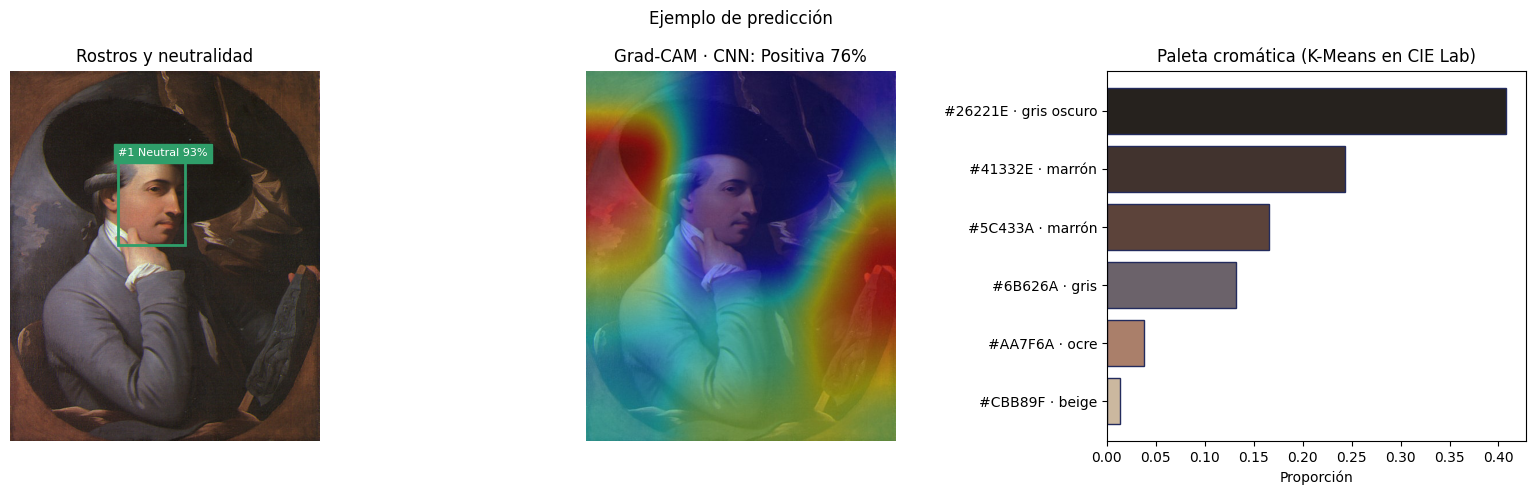

In [23]:
candidatas = fuente.rutas_precargadas() or ([r for r, _ in reparto["prueba"]] if DATOS_LISTOS else [])
if candidatas:
    con_rostro = [r for r in candidatas[:80] if sistema.gestos(cargar_imagen(Path(r).read_bytes()))["estado"] == "ok"]
    ruta_demo = (con_rostro or candidatas)[0]
    pred = predecir_imagen(ruta_demo)
    print("Imagen:", Path(ruta_demo).name)
    print("Obra (CNN):", pred["obra"])
    print("Rostros:", pred["rostros"], "·", pred["mensaje"])
    for d in pred["detecciones"]:
        n = d["neutralidad"] or {}
        print(f"  #{d['id']}: {n.get('etiqueta')} (confianza {n.get('confianza', 0):.2f}, P(neutral) {n.get('probabilidad_neutral', 0):.2f}) "
              f"· emoción {d['emocion']} · calificación {(d['calificacion'] or {}).get('puntaje', 0):.0f}/100")
    print("Excepciones:", [(e["tipo"], e["gravedad"]) for e in pred["excepciones"]] or "ninguna")

    img = cargar_imagen(Path(ruta_demo).read_bytes())
    h, w = img.shape[:2]
    res = sistema.analizar(Path(ruta_demo).read_bytes(), [], modo="dataset", que="la imagen de ejemplo")
    fig, ax = plt.subplots(1, 3, figsize=(16, 5))
    ax[0].imshow(img); ax[0].set_title("Rostros y neutralidad")
    for d in pred["detecciones"]:
        c, n = d["caja"], d["neutralidad"] or {}
        color = "#2F9E6A" if n.get("clase") == "neutral" else "#eb6834"
        ax[0].add_patch(plt.Rectangle((c["x"] * w, c["y"] * h), c["w"] * w, c["h"] * h, fill=False, color=color, lw=2))
        ax[0].text(c["x"] * w, c["y"] * h - 4, f"#{d['id']} {n.get('etiqueta', '')} {n.get('confianza', 0):.0%}",
                   color="white", backgroundcolor=color, fontsize=8)
    if pred["gradcam"] and pred["obra"]:
        gc = cargar_imagen(base64.b64decode(pred["gradcam"].split(",", 1)[1]), permitir_formatos={"JPEG"})
        ax[1].imshow(gc); ax[1].set_title(f"Grad-CAM · CNN: {pred['obra']['etiqueta']} {pred['obra']['probabilidad']:.0%}")
    else:
        ax[1].imshow(img); ax[1].set_title("Sin CNN entrenada: no hay Grad-CAM")
    cols = (res.get("obra") or {}).get("paleta", {}).get("colores", [])
    ax[2].barh(range(len(cols)), [c["proporcion"] for c in cols], color=[c["hex"] for c in cols], edgecolor="#232B5D")
    ax[2].set_yticks(range(len(cols)), [f"{c['hex']} · {c['nombre']}" for c in cols]); ax[2].invert_yaxis()
    ax[2].set_xlabel("Proporción"); ax[2].set_title("Paleta cromática (K-Means en CIE Lab)")
    for a in ax[:2]:
        a.axis("off")
    fig.suptitle("Ejemplo de predicción")
    plt.tight_layout(); plt.show()
else:
    print("No hay imágenes precargadas ni de prueba: sube una imagen en la sección de predicción de la interfaz.")

## 5. Interfaz y resultados
Esta sección reúne los resultados y lanza el aplicativo:

- **Resultados:**
  - curvas de entrenamiento y métricas en prueba, con la comparación con y sin filtros;
  - errores de clasificación;
  - agrupamiento no supervisado;
  - evaluación de la neutralidad con fotos del equipo;
  - exportación a `resultados/resultados.md`.
- **Aplicativo web:** la interfaz vive dentro del notebook y la sirve FastAPI.
  - **Obra y visitante:** sube una obra, activa o detén la cámara, compara la emoción de la obra con tu expresión y guarda fotos etiquetadas para calibrar la neutralidad.
  - **Datos, análisis y predicción:**
    - elige la fuente (carpeta local o Google Drive) y revisa el resumen por grupo;
    - reentrena la CNN;
    - analiza y agrupa las precargadas;
    - sube una imagen para obtener su predicción.

Las celdas de resultados se omiten con un aviso si todavía no hay datos.

### Curvas, métricas, matrices de confusión y comparación con y sin filtros

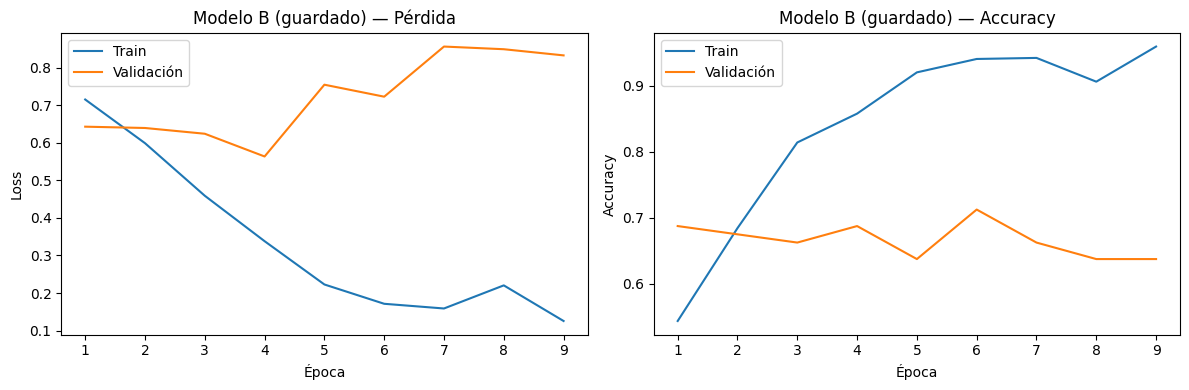

=== resnet18 (elegido) ===
Accuracy  : 0.75
Precision : 0.75
Recall    : 0.75
F1        : 0.75
              precision    recall  f1-score   support

    negativo       0.75      0.75      0.75        40
    positivo       0.75      0.75      0.75        40

    accuracy                           0.75        80
   macro avg       0.75      0.75      0.75        80
weighted avg       0.75      0.75      0.75        80



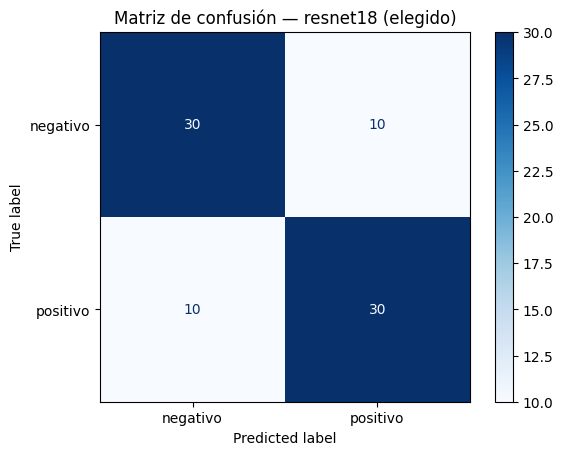

Ablación del preprocesamiento guardada (se elige por pérdida de validación):
  con filtros  val_loss 0.5710 · accuracy prueba 0.750 · F1 0.737
  sin filtros  val_loss 0.5635 · accuracy prueba 0.750 · F1 0.750
Modelo                        Accuracy  Precision  Recall     F1
resnet18 (elegido)               0.750      0.750   0.750  0.750
Misma red, con filtros           0.750      0.778   0.700  0.737
Anterior (cnn3, con filtros)     0.600      0.625   0.500  0.556


In [24]:
if DATOS_LISTOS:
    for nombre, hist in historiales.items():
        graficar(hist, nombre)

    _, _, test_loader = crear_loaders(conj_final)
    resumen = {f"{getattr(modelo_reg, 'arquitectura', 'cnn3')} (elegido)": evaluar(modelo_reg, test_loader, f"{getattr(modelo_reg, 'arquitectura', 'cnn3')} (elegido)", mostrar=True)}
    for filtros, (m, _, _, met, vl) in ablacion.items():
        if m is not modelo_reg:
            resumen[f"Misma red {'con' if filtros else 'sin'} filtros"] = met
    if not ablacion and config.RUTA_METRICAS.exists():
        _m = json.loads(config.RUTA_METRICAS.read_text(encoding="utf-8"))
        _elegida = "con_filtros" if _m.get("filtros_pdi") else "sin_filtros"
        for k, v in _m.get("ablacion", {}).items():
            if k != _elegida:
                resumen[f"Misma red, {k.replace('_', ' ')}"] = v["prueba"]
        if _m.get("ablacion"):
            print("Ablación del preprocesamiento guardada (se elige por pérdida de validación):")
            for k, v in _m["ablacion"].items():
                print(f"  {k.replace('_', ' '):12s} val_loss {v['val_loss']:.4f} · accuracy prueba {v['prueba']['accuracy']:.3f} · F1 {v['prueba']['f1']:.3f}")
    if not METRICAS_ANTERIORES:
        for _r in sorted(config.DIR_MODELOS.parent.glob(f"{config.DIR_MODELOS.name}_respaldo_*")):
            try:
                _a = json.loads((_r / "metricas_cnn.json").read_text(encoding="utf-8"))
            except (OSError, ValueError):
                continue
            if _a.get("arquitectura", "cnn3") != getattr(modelo_reg, "arquitectura", "cnn3"):
                METRICAS_ANTERIORES = _a
                break
    if METRICAS_ANTERIORES:
        resumen[f"Anterior ({METRICAS_ANTERIORES.get('arquitectura', 'cnn3')}, con filtros)"] = METRICAS_ANTERIORES["prueba"]

    print(f"{'Modelo':28s} {'Accuracy':>9s} {'Precision':>10s} {'Recall':>7s} {'F1':>6s}")
    for nombre, m in resumen.items():
        print(f"{nombre:28s} {m['accuracy']:9.3f} {m['precision']:10.3f} {m['recall']:7.3f} {m['f1']:6.3f}")
    if ablacion:
        print("\nAblación del preprocesamiento (se elige por pérdida de validación, no por prueba):")
        for filtros, v in ablacion.items():
            print(f"  {'con filtros PDI' if filtros else 'sin filtros   '}  val_loss {v[4]:.4f} · accuracy prueba {v[3]['accuracy']:.3f} · F1 {v[3]['f1']:.3f}")
else:
    print('Sin modelo entrenado en esta ejecución: no hay métricas que mostrar.')

### Imágenes mal clasificadas

Modelo B (elegido): 20 errores de 80


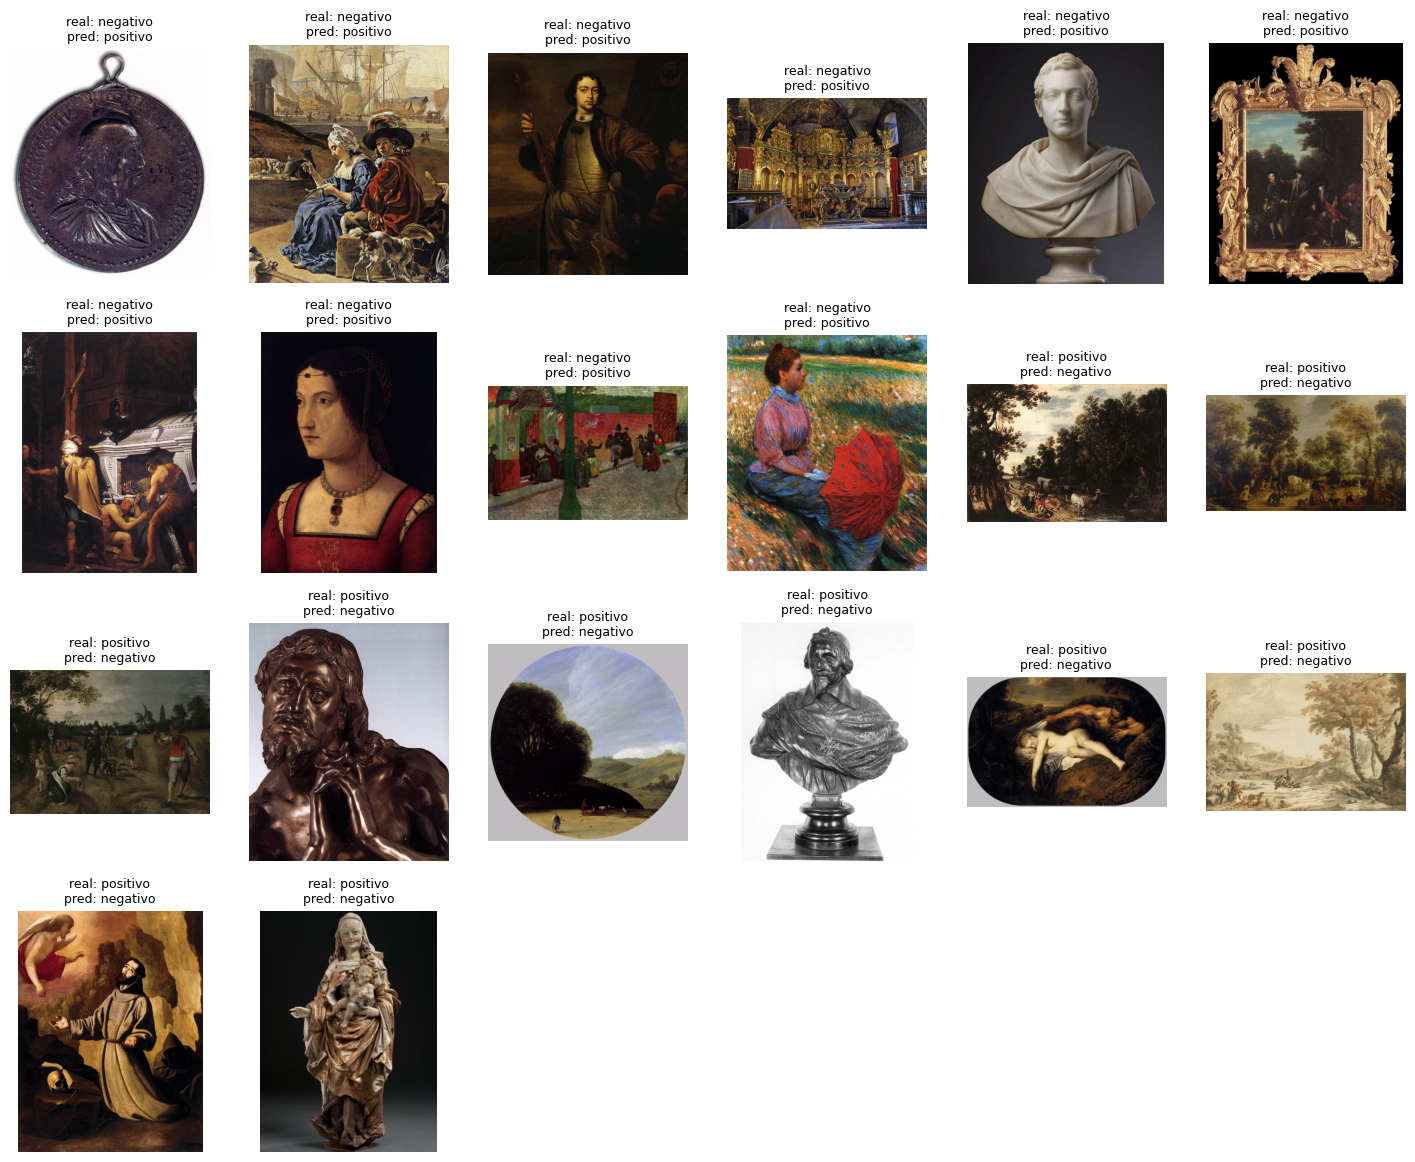

In [25]:
if DATOS_LISTOS:
    mostrar_errores(modelo_reg, conj_final["test"], "Modelo B (elegido)")
else:
    print('Sin modelo entrenado en esta ejecución: no hay errores de clasificación que mostrar.')

### Exploración no supervisada

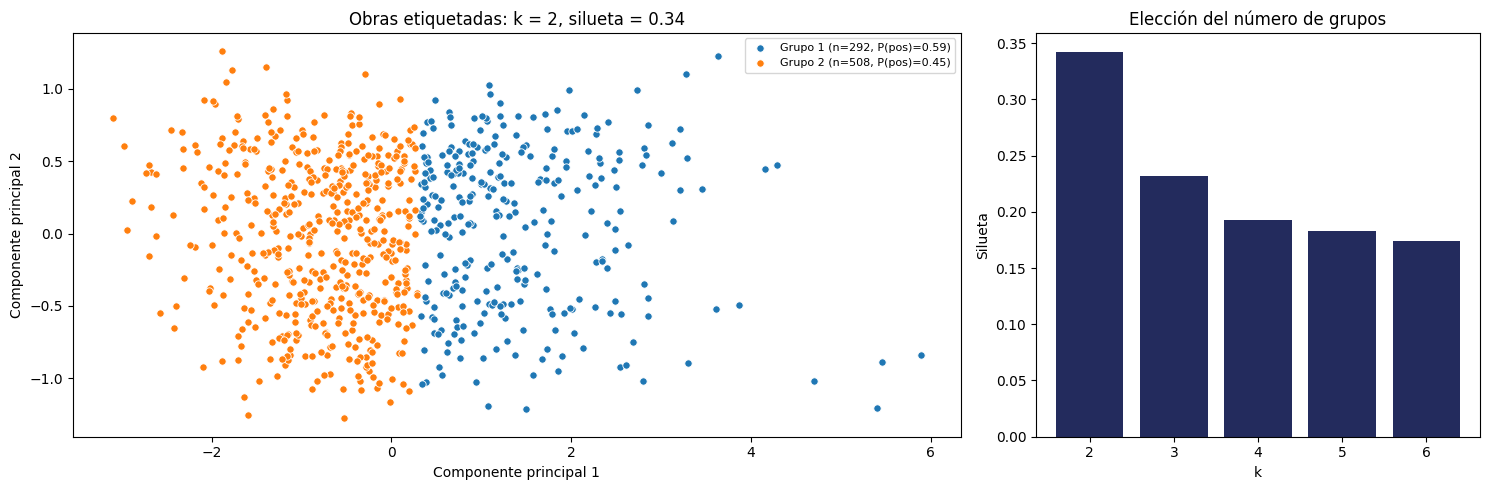

ARI con las etiquetas reales: 0.013 (k elegido) · 0.013 (k = 2)
  Grupo 1: 292 obras · 58% positivas reales · P(positivo) CNN 0.59 · brillo 0.51 · saturación 0.32
  Grupo 2: 508 obras · 45% positivas reales · P(positivo) CNN 0.45 · brillo 0.42 · saturación 0.34


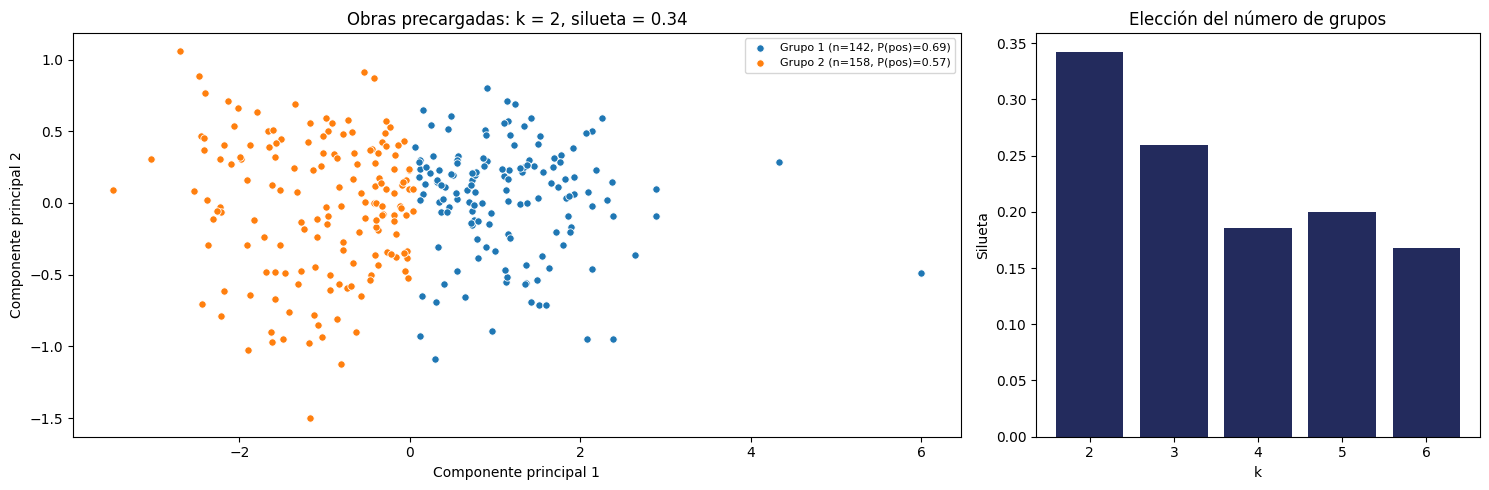

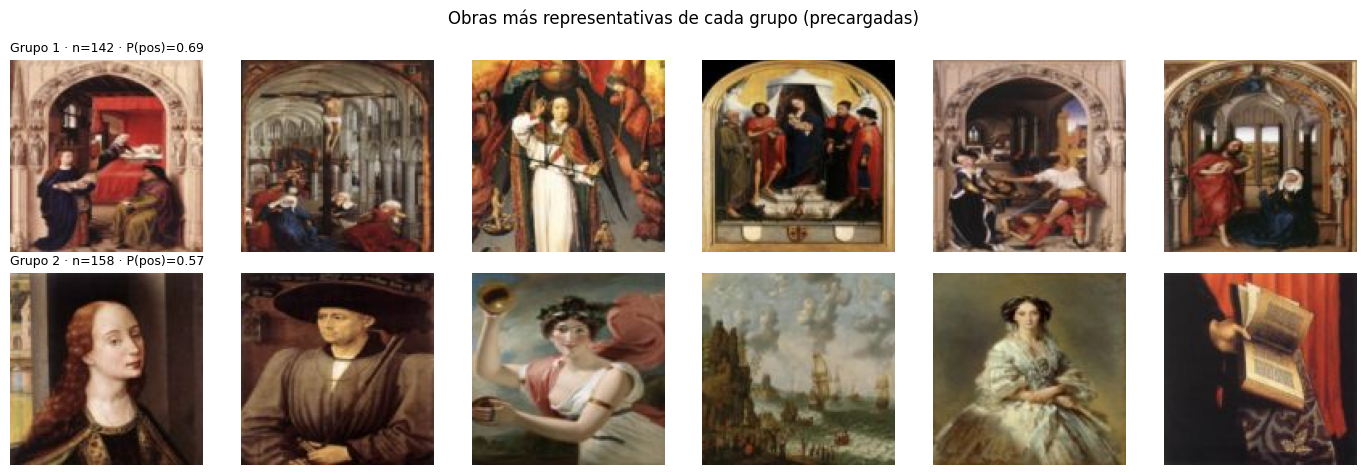

In [26]:
def graficar_agrupamiento(res: dict, titulo: str) -> None:
    fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})
    colores = plt.cm.tab10(np.arange(10))
    for g in res["grupos"]:
        pts = [p for p in res["puntos"] if p["grupo"] == g["id"]]
        ax[0].scatter([p["x"] for p in pts], [p["y"] for p in pts], s=28, color=colores[g["id"] - 1],
                      edgecolor="white", linewidth=0.6, label=f"Grupo {g['id']} (n={g['n']}, P(pos)={g['p_positivo_medio']:.2f})")
    ax[0].set_xlabel("Componente principal 1"); ax[0].set_ylabel("Componente principal 2")
    ax[0].set_title(f"{titulo}: k = {res['k']}, silueta = {res['silueta']:.2f}"); ax[0].legend(fontsize=8)
    ks = list(res["silueta_por_k"]); ax[1].bar(ks, [res["silueta_por_k"][k] for k in ks], color="#232B5D")
    ax[1].set_xlabel("k"); ax[1].set_ylabel("Silueta"); ax[1].set_title("Elección del número de grupos")
    plt.tight_layout(); plt.show()


agrup_etiquetadas = None
if DATOS_LISTOS:
    etiquetadas = reparto["entrenamiento"] + reparto["validacion"] + reparto["prueba"]
    agrup_etiquetadas = agrupar_imagenes([r for r, _ in etiquetadas], sistema.clasificador, sistema.pre,
                                         etiquetas=[y for _, y in etiquetadas], miniaturas=False)
    graficar_agrupamiento(agrup_etiquetadas, "Obras etiquetadas")
    print(f"ARI con las etiquetas reales: {agrup_etiquetadas['ari']} (k elegido) · {agrup_etiquetadas['ari_k2']} (k = 2)")
    for g in agrup_etiquetadas["grupos"]:
        print(f"  Grupo {g['id']}: {g['n']:3d} obras · {g['proporcion_positivas_reales']:.0%} positivas reales · "
              f"P(positivo) CNN {g['p_positivo_medio']:.2f} · brillo {g['brillo']:.2f} · saturación {g['saturacion']:.2f}")
else:
    print('Sin datos etiquetados: se omite el agrupamiento de las obras etiquetadas.')

agrup_precargadas = None
if len(fuente.rutas_precargadas()) >= 6 and sistema.clasificador.disponible:
    agrup_precargadas = agrupar_imagenes(fuente.rutas_precargadas(), sistema.clasificador, sistema.pre)
    graficar_agrupamiento(agrup_precargadas, "Obras precargadas")
    fig, ax = plt.subplots(agrup_precargadas["k"], 6, figsize=(14, 2.4 * agrup_precargadas["k"]), squeeze=False)
    for i, g in enumerate(agrup_precargadas["grupos"]):
        for j in range(6):
            ax[i, j].axis("off")
            if j < len(g["ejemplos"]):
                ax[i, j].imshow(cargar_imagen(base64.b64decode(g["ejemplos"][j]["img"].split(",", 1)[1]), permitir_formatos={"JPEG"}))
        ax[i, 0].set_title(f"Grupo {g['id']} · n={g['n']} · P(pos)={g['p_positivo_medio']:.2f}", loc="left", fontsize=9)
    fig.suptitle("Obras más representativas de cada grupo (precargadas)")
    plt.tight_layout(); plt.show()
else:
    print("Se necesitan al menos 6 precargadas y una CNN entrenada para agruparlas.")

### Evaluación de la neutralidad facial con datos del equipo

Fotos de evaluación: {'neutral': 60, 'no_neutral': 62}
Variante «corregido» (AUC 0.82, 122 fotos del equipo). τ = 0.70 maximiza el índice de Youden: exactitud balanceada 77% con τ = 0.5 → 81% con τ calibrado.

Variante           Detección    AUC  τ Youden  BalAcc τ=0.5  BalAcc τ*
original                1.00  0.799      0.73         0.749      0.781
corregido               1.00  0.818      0.70         0.774      0.814
corregido_clahe         1.00  0.807      0.49         0.797      0.814


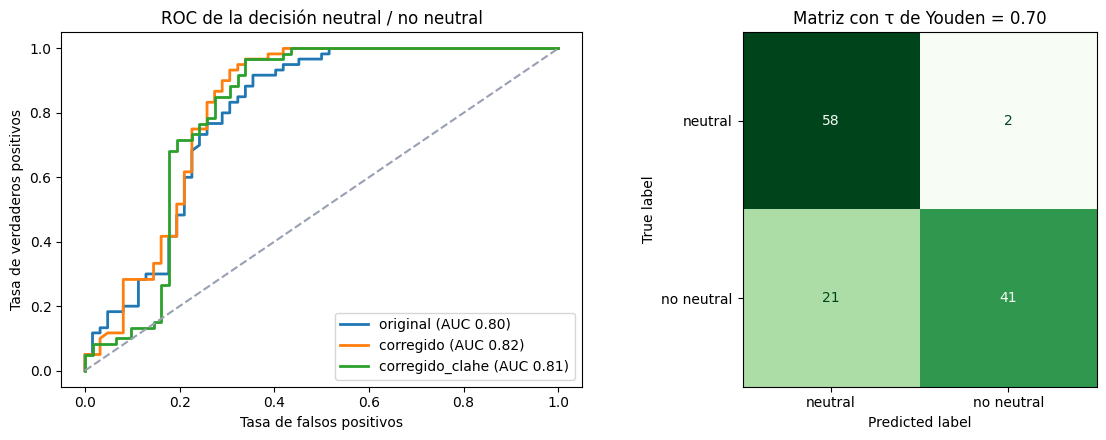

In [27]:
calibracion = calibrar_neutralidad(sistema.gestos, guardar=True)
print("Fotos de evaluación:", calibracion["conteo"])
print(calibracion["justificacion"])
if calibracion.get("elegida"):
    sistema.aplicar_calibracion(leer_calibracion())
    print(f"\n{'Variante':18s} {'Detección':>9s} {'AUC':>6s} {'τ Youden':>9s} {'BalAcc τ=0.5':>13s} {'BalAcc τ*':>10s}")
    for v, m in calibracion["variantes"].items():
        if "auc" in m:
            print(f"{v:18s} {m['tasa_deteccion']:9.2f} {m['auc']:6.3f} {m['umbral_youden']:9.2f} "
                  f"{m['balanced_acc_05']:13.3f} {m['balanced_acc_youden']:10.3f}")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    for v, m in calibracion["variantes"].items():
        if "curva" in m:
            ax[0].plot(m["curva"]["fpr"], m["curva"]["tpr"], lw=2, label=f"{v} (AUC {m['auc']:.2f})")
    ax[0].plot([0, 1], [0, 1], "--", color="#9aa0b4"); ax[0].set_xlabel("Tasa de falsos positivos")
    ax[0].set_ylabel("Tasa de verdaderos positivos"); ax[0].set_title("ROC de la decisión neutral / no neutral"); ax[0].legend()
    cm = np.array(calibracion["variantes"][calibracion["elegida"]]["matriz_confusion_youden"])
    ConfusionMatrixDisplay(cm, display_labels=["neutral", "no neutral"]).plot(ax=ax[1], cmap="Greens", colorbar=False)
    ax[1].set_title(f"Matriz con τ de Youden = {calibracion['variantes'][calibracion['elegida']]['umbral_youden']:.2f}")
    plt.tight_layout(); plt.show()
else:
    print("\nPara evaluar la detección facial con datos propios: activa la cámara en el aplicativo, usa los botones "
          "«Guardar como neutral / no neutral» (≥ 10 fotos por clase, varias personas e iluminaciones) y vuelve a "
          "ejecutar esta celda o pulsa «Calibrar umbral» en la interfaz.")

### Evaluación independiente de la neutralidad (calibración 70 % / prueba 30 %)

Variante «corregido» · calibración 85 fotos (detección 100%) · prueba 37 fotos (detección 100%)
τ elegido SOLO con calibración: 0.70
En prueba → AUC 0.801 · exactitud balanceada τ=0.5: 0.737 · con τ calibrado: 0.816


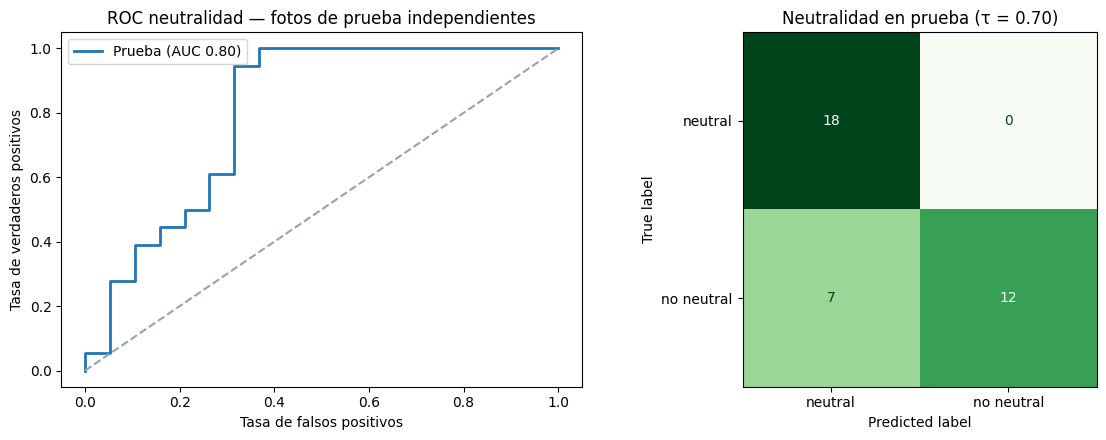

In [28]:
from sklearn.model_selection import train_test_split

eval_neutral_indep = None
_conteo = conteo_fotos()
if min(_conteo.values()) < 15:
    print(f"Se recomiendan ≥ 15 fotos por clase para separar calibración y prueba (hay {_conteo}).")
else:
    variante = calibracion.get("elegida") or "corregido"
    fotos = [(p, 1 if e == "neutral" else 0) for e in ETIQUETAS_EVAL
             for p in sorted((config.DIR_ROSTROS_EVAL / e).glob("*")) if p.suffix.lower() in config.EXTS_IMAGEN]
    cal, prueba = train_test_split(fotos, test_size=0.3, stratify=[y for _, y in fotos], random_state=SEED)

    def _probs(lista):
        res = [(_p_neutral(sistema.gestos, cargar_imagen(p.read_bytes(), p.name), variante), y) for p, y in lista]
        ok = [(pp, y) for pp, y in res if pp is not None]
        return np.array([pp for pp, _ in ok]), np.array([y for _, y in ok]), len(ok) / max(1, len(res))

    ps_c, ys_c, det_c = _probs(cal)
    ps_t, ys_t, det_t = _probs(prueba)
    fpr, tpr, umb = roc_curve(ys_c, ps_c)
    tau = float(np.clip(umb[int(np.argmax(tpr - fpr))], 0.05, 0.95))
    pred = (ps_t >= tau).astype(int)
    eval_neutral_indep = {
        "variante": variante, "tau": tau, "n_calib": len(cal), "n_prueba": len(prueba),
        "deteccion_prueba": det_t, "auc": float(roc_auc_score(ys_t, ps_t)),
        "bal_05": float(balanced_accuracy_score(ys_t, (ps_t >= 0.5).astype(int))),
        "bal_tau": float(balanced_accuracy_score(ys_t, pred)),
        "matriz": confusion_matrix(ys_t, pred, labels=[1, 0]).tolist(),
    }
    e = eval_neutral_indep
    print(f"Variante «{variante}» · calibración {len(cal)} fotos (detección {det_c:.0%}) · prueba {len(prueba)} fotos (detección {det_t:.0%})")
    print(f"τ elegido SOLO con calibración: {tau:.2f}")
    print(f"En prueba → AUC {e['auc']:.3f} · exactitud balanceada τ=0.5: {e['bal_05']:.3f} · con τ calibrado: {e['bal_tau']:.3f}")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ft, tt, _ = roc_curve(ys_t, ps_t)
    ax[0].plot(ft, tt, lw=2, label=f"Prueba (AUC {e['auc']:.2f})"); ax[0].plot([0, 1], [0, 1], "--", color="#9aa0b4")
    ax[0].set_xlabel("Tasa de falsos positivos"); ax[0].set_ylabel("Tasa de verdaderos positivos")
    ax[0].set_title("ROC neutralidad — fotos de prueba independientes"); ax[0].legend()
    ConfusionMatrixDisplay(np.array(e["matriz"]), display_labels=["neutral", "no neutral"]).plot(ax=ax[1], cmap="Greens", colorbar=False)
    ax[1].set_title(f"Neutralidad en prueba (τ = {tau:.2f})")
    plt.tight_layout(); plt.show()

### Exportar resultados

In [29]:
def exportar_resultados() -> Path:
    rep = fuente.reporte
    lineas = ["# Resultados de la última ejecución", ""]
    if rep:
        lineas += [f"- Fuente de datos: {rep['origen']}",
                   "- Imágenes válidas: " + ", ".join(f"{g} {d['validas']}" for g, d in rep["grupos"].items()) +
                   f" · descartadas {len(rep['descartadas'])}"]
    else:
        lineas.append("- Fuente de datos: no se pudo cargar")
    if DATOS_LISTOS and config.RUTA_METRICAS.exists():
        m = json.loads(config.RUTA_METRICAS.read_text(encoding="utf-8"))
        p = m["prueba"]
        lineas += [
            f"- Partición: entrenamiento {m['particion']['entrenamiento']} · validación {m['particion']['validacion']} · prueba {m['particion']['prueba']}",
            f"- Preprocesamiento elegido por validación: {'con' if m['filtros_pdi'] else 'sin'} filtros PDI", "",
            "## CNN de obras (conjunto de prueba)", "",
            "| Modelo | Accuracy | Precision | Recall | F1 |", "|---|---|---|---|---|",
            *[f"| {n} | {r['accuracy']:.3f} | {r['precision']:.3f} | {r['recall']:.3f} | {r['f1']:.3f} |" for n, r in resumen.items()],
            "", f"Matriz de confusión del modelo elegido [[neg→neg, neg→pos], [pos→neg, pos→pos]]: {p['matriz_confusion']}",
        ]
    else:
        lineas += ["", "## CNN de obras", "", "- No se entrenó en esta ejecución (faltan imágenes etiquetadas)."]
    lineas += ["", "## Agrupamiento no supervisado", ""]
    if agrup_etiquetadas:
        lineas.append(f"- Obras etiquetadas: k = {agrup_etiquetadas['k']}, silueta = {agrup_etiquetadas['silueta']}, "
                      f"ARI con las etiquetas = {agrup_etiquetadas['ari']} (k = 2: {agrup_etiquetadas['ari_k2']})")
    if agrup_precargadas:
        lineas.append(f"- Precargadas: k = {agrup_precargadas['k']}, silueta = {agrup_precargadas['silueta']}")
    if not agrup_etiquetadas and not agrup_precargadas:
        lineas.append("- No se ejecutó (faltan imágenes o la CNN).")
    lineas += ["", "## Neutralidad facial", "", f"- {calibracion['justificacion']}"]
    for v, mm in calibracion.get("variantes", {}).items():
        if "auc" in mm:
            lineas.append(f"- {v}: detección {mm['tasa_deteccion']:.0%}, AUC {mm['auc']:.3f}, τ {mm['umbral_youden']:.2f}, "
                          f"exactitud balanceada {mm['balanced_acc_05']:.3f} → {mm['balanced_acc_youden']:.3f}")
    if eval_neutral_indep:
        e = eval_neutral_indep
        lineas += ["", "### Evaluación independiente (fotos de prueba no usadas para elegir τ)", "",
                   f"- Fotos: calibración {e['n_calib']} · prueba {e['n_prueba']} · variante {e['variante']} · τ = {e['tau']:.2f}",
                   f"- Detección de rostro en prueba: {e['deteccion_prueba']:.0%}",
                   f"- AUC prueba: {e['auc']:.3f} · exactitud balanceada τ=0.5: {e['bal_05']:.3f} · con τ calibrado: {e['bal_tau']:.3f}",
                   f"- Matriz [[neutral bien, neutral→no], [no→neutral, no neutral bien]]: {e['matriz']}"]
    lineas += ["", "## Figuras", ""] + [f"![{f.stem}]({f.name})" for f in sorted(config.DIR_RESULTADOS.glob("*.png"))]
    ruta = config.DIR_RESULTADOS / "resultados.md"
    ruta.write_text("\n".join(lineas) + "\n", encoding="utf-8")
    return ruta


print("Resumen escrito en", exportar_resultados())
if CARPETA_PROYECTO_DRIVE:
    _copia = config.CARPETA_PROYECTO / f"resultados_{time.strftime('%Y%m%d_%H%M')}"
    shutil.copytree(config.DIR_RESULTADOS, _copia)
    print("Copia de figuras y resumen en Drive:", _copia)

Resumen escrito en /content/resultados/resultados.md
Copia de figuras y resumen en Drive: /content/drive/MyDrive/Proyecto Final PDI VERSION 3/resultados_20261125_0519


### Conclusiones y cómo interpretar los resultados
- **Clasificación de obras.** La ResNet-18 preentrenada obtiene en prueba (80 obras, 40 por clase) accuracy, precision, recall y F1 de **0.75**, con errores simétricos (10 por clase). La CNN de 3 bloques entrenada desde cero, evaluada sobre la **misma partición**, obtenía accuracy 0.60 y F1 0.556. El intervalo de confianza del 95 % (Wilson) pasa de 0.49–0.70 a **0.65–0.83**, y la prueba binomial frente al azar de p ≈ 0.046 a **p < 0.0001**. La transferencia de aprendizaje es la mejora decisiva con solo 640 imágenes de entrenamiento.
- **Efecto del filtrado PDI.** En la CNN desde cero, el preprocesamiento (mediana + homomórfico + normalización) fue decisivo: sin él la red no aprendía (F1 0.388 frente a 0.556). En la ResNet-18 las dos variantes quedan prácticamente empatadas en validación (pérdida 0.5635 sin filtros frente a 0.5710 con filtros) y se conserva la de menor pérdida, sin filtros. Interpretación: los rasgos aprendidos en ImageNet ya son robustos a la iluminación y al ruido, así que el filtrado aporta sobre todo cuando la red aprende desde cero.
- **Sobreajuste.** La ResNet llega a 0.96 de accuracy en entrenamiento mientras la pérdida de validación sube desde la época 5; Early Stopping recupera los pesos de la época 4.
- **Agrupamiento no supervisado.** ARI = 0.013 (≈ 0): color, textura y bordes no separan por sí solos lo positivo de lo negativo, lo que justifica el modelo supervisado. El grupo de obras más claras tiene más positivas reales (58 % frente a 45 %) y la CNN le asigna mayor P(positivo) (0.59 frente a 0.45).
- **Neutralidad facial con fotos del equipo** (122 fotos: 60 neutrales y 62 no neutrales; detección de rostro 100 %).
  - El recorte corregido (cuadrado, con relleno y alineado por los ojos) separa mejor las clases que el original: AUC 0.818 frente a 0.799.
  - El umbral calibrado τ = 0.70 (índice de Youden) es mayor que 0.5 porque FER+ tiende a llamar «neutral» a las expresiones sutiles; exigir más evidencia para decidir «neutral» corrige ese sesgo.
  - **Evaluación independiente:** con τ elegido solo con 85 fotos de calibración y medido en 37 fotos de prueba no usadas para elegirlo, el AUC es 0.801 y la exactitud balanceada sube de 0.737 (τ = 0.5) a **0.816** (τ calibrado).

### Limitaciones y mejoras
- **Dataset de obras pequeño y subjetivo** (800 obras etiquetadas por el equipo) y una sola partición: mejoraría con varios anotadores, midiendo su acuerdo, y con validación cruzada.
- **Prueba facial pequeña:** con 37 fotos de prueba la exactitud balanceada tiene un margen aproximado de ±12 puntos; conviene ampliar el número de personas y de condiciones de iluminación.
- **Dominio de los modelos faciales:** FER+ y YuNet se entrenaron con fotografías; en pinturas pueden aparecer rostros falsos o no detectados (cada detección muestra su puntaje y calificación).
- **Mejoras posibles:** ajuste fino de más capas de la ResNet o de arquitecturas más recientes, aumento de datos más fuerte y un clasificador de expresiones entrenado con rostros pintados.


### Aplicativo web
La última celda levanta el servidor y abre el navegador (en Colab, muestra un enlace). Para detener el servidor, ejecuta `detener_servidor()` en una celda nueva.

**La interfaz no está escrita en el notebook.** `index.html`, `styles.css` y `app.js` se leen de la carpeta `interfaz/` del proyecto en Drive (`config.CARPETA_WEB`). El servidor FastAPI los sirve junto con la API, por eso la página llega a la CNN: abrirla con `IPython.display.HTML` o con doble clic en el archivo no funcionaría, porque `app.js` llama a `/api/...` en el mismo servidor.


In [30]:
TIPOS_WEB = {".html": "text/html; charset=utf-8", ".css": "text/css; charset=utf-8",
             ".js": "application/javascript; charset=utf-8", ".png": "image/png", ".jpg": "image/jpeg",
             ".jpeg": "image/jpeg", ".svg": "image/svg+xml", ".ico": "image/x-icon", ".json": "application/json"}


def archivo_web(nombre: str) -> Path:
    base = config.CARPETA_WEB.resolve()
    ruta = (base / nombre).resolve()
    if base not in ruta.parents and ruta != base:
        raise FileNotFoundError(nombre)
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe {ruta}")
    return ruta


def revisar_interfaz() -> bool:
    print("Carpeta de la interfaz:", config.CARPETA_WEB)
    faltan = [n for n in config.ARCHIVOS_WEB.values() if not (config.CARPETA_WEB / n).is_file()]
    for clave, n in config.ARCHIVOS_WEB.items():
        r = config.CARPETA_WEB / n
        print(f"  {'✔' if r.is_file() else '✘'} {n:12s} {r.stat().st_size / 1024:7.1f} KB" if r.is_file() else f"  ✘ {n:12s} no encontrado")
    if faltan:
        print(f"\n Faltan {', '.join(faltan)} en {config.CARPETA_WEB}. Sube los tres archivos de la interfaz a esa carpeta\n"
              "  (o cambia config.CARPETA_WEB / config.ARCHIVOS_WEB en la celda de configuración).")
        return False
    html = archivo_web(config.ARCHIVOS_WEB["html"]).read_text(encoding="utf-8", errors="replace")
    for clave in ("css", "js"):
        nombre = config.ARCHIVOS_WEB[clave]
        if not re.search(r'(href|src)=["\'](\./)?' + re.escape(nombre) + r'["\']', html):
            print(f"⚠ index.html no enlaza «{nombre}» con una ruta relativa (href=\"{nombre}\" / src=\"{nombre}\"): revísalo.")
    return True


INTERFAZ_LISTA = revisar_interfaz()

Carpeta de la interfaz: /content/drive/MyDrive/Proyecto Final PDI VERSION 3/interfaz
  ✔ index.html      17.1 KB
  ✔ styles.css      31.1 KB
  ✔ app.js          83.9 KB


### Servidor (FastAPI)

In [31]:
app = FastAPI(title="Expresión humana en el arte · PDI UAO", version="2.0")
app.add_middleware(CORSMiddleware, allow_origins=["*"], allow_methods=["*"], allow_headers=["*"])


SIN_CACHE = {"Cache-Control": "no-store"}


def _servir_web(nombre: str) -> Response:
    try:
        ruta = archivo_web(nombre)
    except FileNotFoundError:
        return HTMLResponse(f"<h2>Falta {nombre}</h2><p>Súbelo a <code>{config.CARPETA_WEB}</code> y recarga la página.</p>",
                            status_code=404)
    return Response(ruta.read_bytes(), media_type=TIPOS_WEB.get(ruta.suffix.lower(), "application/octet-stream"),
                    headers=SIN_CACHE)


@app.get("/", response_class=HTMLResponse)
def inicio():
    return _servir_web(config.ARCHIVOS_WEB["html"])


@app.get("/api/estado")
def estado():
    info = sistema.estado()
    info["descargas"] = errores_descarga
    return info


@app.get("/api/metricas")
def metricas():
    if not config.RUTA_METRICAS.exists():
        raise HTTPException(404, "Aún no hay métricas: ejecuta la celda de entrenamiento.")
    return json.loads(config.RUTA_METRICAS.read_text(encoding="utf-8"))


@app.post("/api/frame")
def analizar_frame(frame: UploadFile = File(...)):
    try:
        return sistema.analizar_frame(frame.file.read())
    except ErrorProceso as e:
        return JSONResponse({"estado": "error", "excepciones": [e.a_dict()]}, status_code=200)


@app.post("/api/analizar")
def analizar(
    obra: Optional[UploadFile] = File(None),
    frames: Optional[List[UploadFile]] = File(None),
    rostro: Optional[UploadFile] = File(None),
    tiempos: Optional[str] = Form(None),
    modo: str = Form("visitante"),
):
    obra_bytes = obra.file.read() if obra is not None else None
    lista = [f.file.read() for f in (frames or [])]
    if rostro is not None:
        lista.append(rostro.file.read())
    try:
        marcas = json.loads(tiempos) if tiempos else []
    except json.JSONDecodeError:
        marcas = []
    marcas = [float(m) for m in marcas] + [float(i * 500) for i in range(len(marcas), len(lista))]
    if obra_bytes is None and not lista:
        raise HTTPException(400, "Envía al menos la obra o un fotograma del rostro.")
    if modo == "dataset":
        if obra_bytes is None:
            raise HTTPException(400, "En modo dataset debes enviar la imagen en el campo «obra».")
        return sistema.analizar(obra_bytes, [], modo="dataset", que="la imagen subida")
    return sistema.analizar(obra_bytes, list(zip(lista, marcas)))


_HTTP_ERROR = {"fuente_no_encontrada": 404, "imagen_no_encontrada": 404,
               "fuente_no_disponible": 503, "estructura_invalida": 422, "sin_datos": 409, "sin_precargadas": 409,
               "entrenamiento_en_curso": 409}


def _respuesta_error(e: ErrorProceso) -> JSONResponse:
    return JSONResponse({"estado": "error", "error": e.a_dict(), "dataset": sistema.dataset.estado()},
                        status_code=_HTTP_ERROR.get(e.tipo, 400))


@app.get("/api/dataset/estado")
def dataset_estado():
    return sistema.dataset.estado()


@app.get("/api/dataset/aleatorias")
def dataset_aleatorias(n: int = 6, excluir: str = ""):
    try:
        res = sistema.dataset.aleatorias(n, [x for x in excluir.split("|") if x])
        res["estado"] = "ok"
        return res
    except ErrorProceso as e:
        return _respuesta_error(e)


@app.get("/api/dataset/imagen")
def dataset_imagen(nombre: str):
    try:
        ruta = sistema.dataset.ruta(nombre)
    except ErrorProceso as e:
        return _respuesta_error(e)
    tipo = "image/png" if ruta.suffix.lower() == ".png" else "image/jpeg"
    return FileResponse(ruta, media_type=tipo, headers={"Cache-Control": "public, max-age=86400"})


@app.post("/api/dataset/analizar")
def dataset_analizar(nombre: str = Form(...)):
    try:
        return sistema.analizar_dataset(nombre)
    except ErrorProceso as e:
        return _respuesta_error(e)


print("API lista:", len([r for r in app.routes if getattr(r, "path", "").startswith("/api")]), "endpoints")


entrenamiento_estado = {"en_curso": False, "log": [], "resultado": None, "error": None, "inicio": None}


@app.get("/api/datos/estado")
def datos_estado():
    r = fuente.resumen()
    r["por_defecto"] = {"tipo": config.FUENTE_TIPO, "local": str(config.RUTA_LOCAL), "drive": str(config.RUTA_DRIVE), "colab": EN_COLAB}
    r["entrenamiento"] = {k: v for k, v in entrenamiento_estado.items() if k != "log"} | {"log": entrenamiento_estado["log"][-8:]}
    r["modelo"] = {"filtros": sistema.clasificador.filtros, "metricas": json.loads(config.RUTA_METRICAS.read_text(encoding="utf-8"))["prueba"]
                   if config.RUTA_METRICAS.exists() else None}
    return r


@app.post("/api/datos/cargar")
def datos_cargar(tipo: str = Form("local"), ruta: str = Form("")):
    if entrenamiento_estado["en_curso"]:
        return _respuesta_error(ErrorProceso("entrenamiento_en_curso", "Espera a que termine el reentrenamiento.", "error", "FuenteDeDatos"))
    try:
        return fuente.cargar(tipo, ruta)
    except ErrorProceso as e:
        return _respuesta_error(e)


def _reentrenar():
    est = entrenamiento_estado
    try:
        est["log"].append("Preparando imágenes…")
        rep_local = dividir(fuente.etiquetadas())
        conj = preparar_conjuntos(rep_local, sistema.clasificador.filtros or not sistema.clasificador.disponible)
        modelo, hist, mejor, metricas, _ = entrenar_modelo_b(conj, progreso=est["log"].append)
        guardar_modelo(modelo, conj, hist, mejor, metricas, rep_local)
        sistema.recargar_cnn()
        est["resultado"] = {"prueba": metricas, "mejor_epoca": mejor, "particion": {k: len(v) for k, v in rep_local.items()}}
        est["log"].append(f"Listo: accuracy de prueba {metricas['accuracy']:.3f}, F1 {metricas['f1']:.3f}.")
    except ErrorProceso as e:
        est["error"] = e.a_dict()
    except Exception as e:
        est["error"] = {"tipo": "servidor", "gravedad": "error", "modulo": "Entrenamiento", "mensaje": f"El entrenamiento falló: {e}"}
    finally:
        est["en_curso"] = False


@app.post("/api/entrenar")
def entrenar_api():
    if entrenamiento_estado["en_curso"]:
        return _respuesta_error(ErrorProceso("entrenamiento_en_curso", "Ya hay un entrenamiento en curso.", "error", "Entrenamiento"))
    if not fuente.reporte or not fuente.reporte["listo_entrenar"]:
        return _respuesta_error(ErrorProceso("sin_datos", f"La fuente activa no tiene al menos {config.MIN_POR_CLASE} imágenes válidas "
                                             "por clase.", "error", "Entrenamiento"))
    entrenamiento_estado.update({"en_curso": True, "log": [], "resultado": None, "error": None, "inicio": time.time()})
    threading.Thread(target=_reentrenar, daemon=True, name="reentrenamiento").start()
    return {"estado": "iniciado"}


@app.post("/api/predecir")
def predecir_api(imagen: UploadFile = File(...)):
    return sistema.predecir(imagen.file.read(), imagen.filename or "la imagen subida")


@app.post("/api/dataset/predecir")
def predecir_precargada(nombre: str = Form(...)):
    try:
        return sistema.predecir(sistema.dataset.leer(nombre), nombre)
    except ErrorProceso as e:
        return _respuesta_error(e)


@app.post("/api/agrupamiento")
def agrupamiento_api():
    if not sistema.clasificador.disponible:
        return _respuesta_error(ErrorProceso("sin_datos", "La CNN no está disponible.", "error", "AgrupamientoNoSupervisado"))
    try:
        return agrupar_imagenes(fuente.rutas_precargadas(), sistema.clasificador, sistema.pre)
    except ErrorProceso as e:
        return _respuesta_error(e)


@app.get("/api/rostros/estado")
def rostros_estado():
    return {"conteo": conteo_fotos(), "minimo": config.MIN_FOTOS_CALIBRACION, "calibracion": sistema.calibracion}


@app.post("/api/rostros/guardar")
def rostros_guardar(frame: UploadFile = File(...), etiqueta: str = Form(...)):
    try:
        return {"conteo": guardar_foto(frame.file.read(), etiqueta)}
    except ErrorProceso as e:
        return _respuesta_error(e)


@app.post("/api/rostros/calibrar")
def rostros_calibrar():
    res = calibrar_neutralidad(sistema.gestos, guardar=True)
    if res.get("elegida"):
        sistema.aplicar_calibracion(leer_calibracion())
    return res


@app.get("/{archivo}")
def archivo_interfaz(archivo: str):
    return _servir_web(archivo)

API lista: 8 endpoints


### Lanzar el aplicativo

In [32]:
def _puerto_libre(inicio: int, intentos: int = 10) -> int:
    for p in range(inicio, inicio + intentos):
        with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
            try:
                s.bind(("127.0.0.1", p))
                return p
            except OSError:
                continue
    raise RuntimeError(f"Los puertos {inicio}-{inicio + intentos - 1} están ocupados. Cambia config.PUERTO.")


def detener_servidor():
    srv, hilo = globals().get("servidor"), globals().get("hilo_servidor")
    if srv is not None and hilo is not None and hilo.is_alive():
        srv.should_exit = True
        hilo.join(timeout=10)
        print("Servidor detenido.")


detener_servidor()
PUERTO_APP = _puerto_libre(config.PUERTO)
servidor = uvicorn.Server(uvicorn.Config(app, host="127.0.0.1", port=PUERTO_APP, log_level="warning"))
URL_APP = f"http://localhost:{PUERTO_APP}"

if EN_JUPYTER:
    hilo_servidor = threading.Thread(target=servidor.run, daemon=True, name="servidor-pdi")
    hilo_servidor.start()
    for _ in range(150):
        if servidor.started or not hilo_servidor.is_alive():
            break
        time.sleep(0.1)
    if not servidor.started:
        raise RuntimeError("El servidor no pudo iniciar. Revisa que el puerto esté libre y vuelve a ejecutar la celda.")
    from IPython.display import HTML, display
    try:
        from google.colab import output as _colab_output
        _colab_output.serve_kernel_port_as_window(PUERTO_APP, anchor_text="Abrir el aplicativo")
    except ImportError:
        display(HTML(f'<p style="font-size:1.1em">✅ Aplicativo en ejecución: <a href="{URL_APP}" target="_blank">{URL_APP}</a> '
                     f'· para detenerlo ejecuta <code>detener_servidor()</code></p>'))
        if config.ABRIR_NAVEGADOR and not os.environ.get("NO_ABRIR"):
            webbrowser.open(URL_APP)
else:
    print(f"Aplicativo en {URL_APP} (Ctrl+C para detener)")
    if config.ABRIR_NAVEGADOR and not os.environ.get("NO_ABRIR"):
        threading.Timer(1.5, webbrowser.open, args=(URL_APP,)).start()
    servidor.run()

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

### Exponer el aplicativo a Internet (opcional, Colab)
Genera un enlace público `https://….loca.lt` con **Localtunnel**. Útil si el enlace de Colab no abre o si quieres usar la cámara desde otro dispositivo.

In [33]:
import subprocess, threading, re, time, urllib.request, os

def _leer(url, t=8):
    req = urllib.request.Request(url, headers={"User-Agent": "curl/8.0"})
    return urllib.request.urlopen(req, timeout=t).read().decode().strip()

def ip_publica():
    for url in ("https://loca.lt/mytunnelpassword", "https://api.ipify.org", "https://ipv4.icanhazip.com"):
        try:
            ip = _leer(url)
            if re.fullmatch(r"\d{1,3}(\.\d{1,3}){3}", ip):
                return ip, url
        except Exception as e:
            print(f"  · {url} no respondió ({type(e).__name__})")
    return None, None

def lanzar_tunel(cmd, patron, espera=25):
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    hallada = {}
    def lector():
        for linea in proc.stdout:
            m = re.search(patron, linea)
            if m and "url" not in hallada:
                hallada["url"] = m.group(0)
    threading.Thread(target=lector, daemon=True).start()
    fin = time.time() + espera
    while time.time() < fin and "url" not in hallada and proc.poll() is None:
        time.sleep(0.3)
    if "url" not in hallada:
        proc.terminate()
        return None, None
    return proc, hallada["url"]

if config.TUNEL_PUBLICO and EN_COLAB:
    proc_tunel = None
    subprocess.run(["npm", "install", "-g", "localtunnel", "--silent"], check=False)
    ip, origen = ip_publica()
    print(f"🔑 Contraseña del enlace (IP pública): {ip}   (obtenida de {origen})" if ip
          else "No se pudo obtener la IP pública; se intentará igual.")
    proc_tunel, url = lanzar_tunel(["lt", "--port", str(PUERTO_APP)], r"https://[\w.-]+\.loca\.lt")

    if proc_tunel is None:
        print("Localtunnel no respondió. Probando con Cloudflare…")
        if not os.path.exists("/usr/local/bin/cloudflared"):
            subprocess.run(["wget", "-q", "-O", "/usr/local/bin/cloudflared",
                            "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64"], check=True)
            os.chmod("/usr/local/bin/cloudflared", 0o755)
        proc_tunel, url = lanzar_tunel(["cloudflared", "tunnel", "--url", f"http://127.0.0.1:{PUERTO_APP}"],
                                       r"https://[\w-]+\.trycloudflare\.com", espera=40)
        if url:
            print("(Este enlace no pide contraseña.)")

    if url:
        display(HTML(f'<p style="font-size:1.1em">🌐 Enlace público: <a href="{url}" target="_blank">{url}</a></p>'))
        print("El túnel sigue abierto mientras el servidor corra. Para cerrarlo: proc_tunel.terminate()")
    else:
        print("✘ No se pudo abrir ningún túnel. Usa el enlace interno de Colab de la celda anterior.")
else:
    print("Túnel público desactivado (solo se usa en Colab con config.TUNEL_PUBLICO = True).")

🔑 Contraseña del enlace (IP pública): 136.85.168.76   (obtenida de https://loca.lt/mytunnelpassword)


El túnel sigue abierto mientras el servidor corra. Para cerrarlo: proc_tunel.terminate()
